# Notebook_B (Sinh viên B): chia dữ liệu, năm mô hình, tinh chỉnh, RQ3, SHAP, chẩn đoán

**Đề tài**: Tải sạc xe điện nơi làm việc và đổi chế độ 2020 (ACN-Data, Caltech và JPL)

**Khung SDG**: SDG 7 và 11: sạc xe điện, giao thông bền vững.

**Vai trò**: Sinh viên B nhận `data/processed/feat.parquet` và `manifest.json` từ Notebook_A, làm Bước 4 và Bước 6, vẽ hình so sánh mô hình, giải thích chỉ số, tinh chỉnh, câu hỏi thứ ba, SHAP và chẩn đoán vì sao tốt hay chưa tốt. Mọi bảng lưu `report/table_*.csv`, mọi hình `report/fig_rq2_*.png`, `fig_rq3_*.png`.

**Quy tắc**: không chạm tập kiểm thử khi tinh chỉnh; mỗi kết luận phải kèm số; báo cáo slot 3 thứ Tư và thứ Bảy (12:30 đến 14:45).

## Vừa làm vừa hỏi AI và ghi Audit Log: cách làm nhẹ nhàng, không rối

**Tinh thần**: AI là bạn cùng làm, không phải người làm thay. Bạn được hỏi AI bất cứ lúc nào; điều duy nhất phải giữ là *kiểm tra một lần* trước khi dùng và *ghi lại 2 phút* nếu câu hỏi đó thay đổi việc bạn làm.

**Khi nào hỏi AI** (theo thứ tự):
1. Đọc ô hướng dẫn của bước đang làm (1 phút).
2. Thử tự làm 15 phút.
3. Bí quá 15 phút thì hỏi AI với mẫu: *"Tôi đang làm Bước X của dự án Y. Dữ liệu có cột A, B, C. Tôi muốn Z. Đây là code và lỗi: ... Hãy giải thích nguyên nhân và sửa, giữ nguyên tên biến."*
4. Chạy thử code AI đưa trên dữ liệu thật; so một con số bằng tay hoặc bằng cách thứ hai.
5. Nếu vẫn bí sau 30 phút, ghi lại lỗi và hỏi giảng viên ở kênh nhóm.

**Ghi Audit Log thế nào cho không áp lực**: chỉ ghi các prompt *đã thay đổi việc bạn làm* (thường 3 đến 5 prompt một tuần, 15 đến 20 cả kỳ). Mỗi dòng 5 ô, điền trong 2 phút ngay khi dùng, không để cuối tuần:

| Ngày, bước | Prompt (rút gọn) | AI trả lời gì (1 dòng) | Tôi kiểm tra hoặc sửa gì | Dùng vào đâu |
|---|---|---|---|---|
| 09/09, Bước 3 | viết truy vấn trung bình trượt 7 ngày theo trạm | đưa AVG OVER ROWS 6 PRECEDING | thiếu PARTITION BY site_num, thêm và thử 2 trạm | Q3 trong sql/queries.sql |

Cột thứ tư chính là *Human Delta* và là thứ hội đồng hỏi; ghi thật, kể cả khi AI đúng ("kiểm tra bằng 10 dòng tính tay, khớp"). Ba lần bạn phát hiện AI sai trong cả kỳ là đủ yêu cầu.

**Nhịp làm việc**: mỗi ngày 1,5 đến 2 giờ vào đúng bước của tuần, xong một ô thì commit; thứ Ba và thứ Sáu slot 1 báo cáo năm mục đúng tiến độ, dù kết quả chưa đẹp. Siêng và đúng nhịp quan trọng hơn giỏi: nhóm báo cáo đều 6 lần trong 3 tuần luôn có bài, nhóm im lặng đến tuần 3 thường không kịp.

## Bước 0: kiểm tra bàn giao từ Notebook_A

Đọc `manifest.json`, so mã băm và số dòng với file parquet; nếu lệch thì báo Sinh viên A chạy lại Notebook_A trước khi tiếp tục.

In [1]:
# ============================================================
# NOTEBOOK B - STEP 0
# Check handover from Notebook A
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
import duckdb
import warnings
import time

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error as MAE,
    mean_squared_error as MSE,
    f1_score,
    average_precision_score,
    roc_auc_score
)

warnings.filterwarnings("ignore")
np.random.seed(42)


# ============================================================
# PROJECT ROOT
# ============================================================

ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent


FEAT_FILE = ROOT / "data/processed/feat.parquet"
MANIFEST_FILE = ROOT / "data/processed/manifest.json"


# ============================================================
# READ MANIFEST
# ============================================================

with open(
    MANIFEST_FILE,
    "r",
    encoding="utf-8"
) as f:
    man = json.load(f)


# ============================================================
# CHECK MD5
# ============================================================

with open(
    FEAT_FILE,
    "rb"
) as f:
    actual_md5 = hashlib.md5(
        f.read()
    ).hexdigest()


assert actual_md5 == man["md5"], (
    "feat.parquet differs from the file "
    "recorded in manifest.json"
)


# ============================================================
# LOAD FEATURE TABLE
# ============================================================

feat = pd.read_parquet(
    FEAT_FILE
)


assert len(feat) == man["rows"], (
    "Row count differs from manifest.json"
)


# ============================================================
# DUCKDB
# ============================================================

con = duckdb.connect()

con.register(
    "feat",
    feat
)


# ============================================================
# DISPLAY
# ============================================================

print("=" * 70)
print("HANDOVER CHECK")
print("=" * 70)

print(
    "Rows:",
    man["rows"]
)

print(
    "Columns:",
    len(man["cols"])
)

print(
    "Time range:",
    man["time_min"],
    "→",
    man["time_max"]
)

print(
    "MD5:",
    man["md5"]
)

print("\nfeat shape:")
print(feat.shape)

print("\nColumns:")
print(feat.columns.tolist())

print("\n✅ HANDOVER OK")


# ============================================================
# FIGURE STYLE
# ============================================================

def style(ax):
    ax.spines[
        ["top", "right"]
    ].set_visible(False)

HANDOVER CHECK
Rows: 56229
Columns: 15
Time range: 2018-04-25 18:00:00+07:00 → 2021-09-14 21:00:00+07:00
MD5: 012ed2bab54052bbef82b484b3dfbfc5

feat shape:
(56229, 15)

Columns:
['site', 'ts', 'kwh', 'sessions', 'temp', 'price', 'hr', 'dow', 'mon', 'k_lag1', 'k_lag24', 'k_lag168', 'k_ma24', 'y_1h', 'y_24h']

✅ HANDOVER OK


## Bước 4: chia dữ liệu và bảng đặc trưng

**Làm gì**: chọn `X_cols` từ `report/table_columns.csv` của A; chia theo thời gian (hoặc theo đơn vị với leave-out); tính mốc naive; xuất bảng đặc trưng (tên, cách tính, nhóm) cho bài.

**Vì sao chia theo thời gian**: dữ liệu tương lai không được rò vào huấn luyện; chia ngẫu nhiên cho kết quả đẹp giả (Bergmeir và Benitez, 2012).

**Kiểm tra**: mọi thời điểm của test sau train; số dòng test đủ lớn (trên 10% và trên 3 nghìn dòng).

In [2]:
# ============================================================
# STEP 4
# Time-based train/test split + feature table + naive baseline
# Target: EV charging load 24 hours ahead
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_error as MAE


# ============================================================
# 1. PREPARE FEATURE DATA
# ============================================================

feat_model = feat.copy()

# Normalize timestamp to UTC
feat_model["ts"] = pd.to_datetime(
    feat_model["ts"],
    utc=True,
    errors="coerce"
)


# Keep rows that have:
# - timestamp
# - target 24h ahead
# - weekly lag required by naive baseline
feat_model = feat_model.dropna(
    subset=[
        "ts",
        "y_24h",
        "k_lag168"
    ]
).copy()


print("=" * 70)
print("STEP 4 - DATA PREPARATION")
print("=" * 70)

print(
    "Rows available for modelling:",
    len(feat_model)
)


# ============================================================
# 2. SITE CODE
# ============================================================

sites = sorted(
    feat_model["site"]
    .dropna()
    .unique()
)

site_map = {
    site: i
    for i, site in enumerate(sites)
}

feat_model["site_code"] = (
    feat_model["site"]
    .map(site_map)
)


print(
    "Site mapping:",
    site_map
)


# ============================================================
# 3. MODEL FEATURES
# ============================================================

X_cols = [
    "kwh",
    "sessions",
    "k_lag1",
    "k_lag24",
    "k_lag168",
    "k_ma24",
    "temp",
    "price",
    "hr",
    "dow",
    "mon",
    "site_code"
]


# ============================================================
# 4. TIME SPLIT
#
# Train: 2018-2019
# Test : 2020-2021
#
# This follows Notebook B and includes
# the 2020 regime/pandemic shift in test.
# ============================================================

CUT = pd.Timestamp(
    "2020-01-01",
    tz="UTC"
)


train = (
    feat_model[
        feat_model["ts"] < CUT
    ]
    .copy()
)

test = (
    feat_model[
        feat_model["ts"] >= CUT
    ]
    .copy()
)


print("\n" + "=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print(
    "Train rows:",
    len(train)
)

print(
    "Test rows:",
    len(test)
)

print(
    "Train range:",
    train["ts"].min(),
    "→",
    train["ts"].max()
)

print(
    "Test range:",
    test["ts"].min(),
    "→",
    test["ts"].max()
)


# ============================================================
# 5. CHECK MISSING FEATURES
# ============================================================

print("\nMissing features BEFORE imputation:")

missing_before = (
    train[X_cols]
    .isna()
    .sum()
)

print(
    missing_before[
        missing_before > 0
    ]
)


# ============================================================
# 6. IMPUTE FEATURES USING TRAIN ONLY
#
# Important:
# Do NOT calculate medians using test data.
# ============================================================

fill_values = (
    train[X_cols]
    .median()
)


train[X_cols] = (
    train[X_cols]
    .fillna(fill_values)
)

test[X_cols] = (
    test[X_cols]
    .fillna(fill_values)
)


print("\nMissing features AFTER imputation:")

print(
    "Train:",
    int(
        train[X_cols]
        .isna()
        .sum()
        .sum()
    )
)

print(
    "Test:",
    int(
        test[X_cols]
        .isna()
        .sum()
        .sum()
    )
)


# ============================================================
# 7. X / Y
# ============================================================

X_tr = train[X_cols]
y_tr = train["y_24h"]

X_te = test[X_cols]
y_te = test["y_24h"]


# ============================================================
# 8. NAIVE BASELINE
#
# Keep the baseline specified by Notebook B:
# weekly lag
# ============================================================

naive_pred = test["k_lag168"]

naive = MAE(
    y_te,
    naive_pred
)


print("\n" + "=" * 70)
print("NAIVE BASELINE")
print("=" * 70)

print(
    "MAE naive:",
    round(
        naive,
        3
    )
)


# ============================================================
# 9. FEATURE TABLE
# ============================================================

feature_info = {
    "kwh": (
        "current hourly charging load",
        "lag/rolling"
    ),

    "sessions": (
        "number of active charging sessions",
        "exogenous/structural"
    ),

    "k_lag1": (
        "charging load 1 hour earlier",
        "lag/rolling"
    ),

    "k_lag24": (
        "charging load 24 hours earlier",
        "lag/rolling"
    ),

    "k_lag168": (
        "charging load 168 hours earlier",
        "lag/rolling"
    ),

    "k_ma24": (
        "rolling mean of previous/current 24 hours",
        "lag/rolling"
    ),

    "temp": (
        "hourly Pasadena temperature",
        "exogenous/structural"
    ),

    "price": (
        "hourly CAISO electricity price",
        "exogenous/structural"
    ),

    "hr": (
        "hour of day",
        "calendar"
    ),

    "dow": (
        "day of week",
        "calendar"
    ),

    "mon": (
        "month",
        "calendar"
    ),

    "site_code": (
        "encoded charging site",
        "exogenous/structural"
    )
}


feature_rows = []

for c in X_cols:

    description, group = (
        feature_info[c]
    )

    feature_rows.append(
        [
            c,
            description,
            group
        ]
    )


feat_table = pd.DataFrame(
    feature_rows,
    columns=[
        "feature",
        "description",
        "group"
    ]
)


feat_table.to_csv(
    ROOT /
    "report/table_features.csv",
    index=False
)


print("\n" + "=" * 70)
print("FEATURE TABLE")
print("=" * 70)

print(feat_table)


# ============================================================
# 10. REQUIRED CHECKS
# ============================================================

assert (
    train["ts"].max()
    <
    test["ts"].min()
), "Test data must come after training data."


assert len(test) > 3000, (
    "Test set has fewer than 3000 rows."
)


assert len(test) > (
    0.1 * len(train)
), "Test set is too small."


assert not any(
    c.startswith("y_")
    for c in X_cols
), "Future target leaked into features."


print("\n" + "=" * 70)
print("STEP 4 DONE ✅")
print("=" * 70)

print("✅ Time split valid")
print("✅ Test set sufficiently large")
print("✅ No y_* target leakage")
print("✅ Feature missing values handled using train only")

print("\nSaved:")
print(
    ROOT /
    "report/table_features.csv"
)

STEP 4 - DATA PREPARATION
Rows available for modelling: 55845
Site mapping: {'caltech': 0, 'jpl': 1}

TRAIN / TEST SPLIT
Train rows: 26018
Test rows: 29827
Train range: 2018-05-02 11:00:00+00:00 → 2019-12-31 23:00:00+00:00
Test range: 2020-01-01 00:00:00+00:00 → 2021-09-13 14:00:00+00:00

Missing features BEFORE imputation:
temp    24
dtype: int64

Missing features AFTER imputation:
Train: 0
Test: 0

NAIVE BASELINE
MAE naive: 5.77

FEATURE TABLE
      feature                                description                 group
0         kwh               current hourly charging load           lag/rolling
1    sessions         number of active charging sessions  exogenous/structural
2      k_lag1               charging load 1 hour earlier           lag/rolling
3     k_lag24             charging load 24 hours earlier           lag/rolling
4    k_lag168            charging load 168 hours earlier           lag/rolling
5      k_ma24  rolling mean of previous/current 24 hours           lag/rolli

### 6.0. Giải thích các chỉ số trước khi chạy

| Chỉ số | Công thức | Dùng khi | Đọc thế nào | Bẫy thường gặp |
|---|---|---|---|---|
| MAE | trung bình của |y − ŷ| | hồi quy, đơn vị như mục tiêu | càng nhỏ càng tốt; so với mốc naive | không phạt lỗi lớn |
| RMSE | căn của trung bình (y − ŷ)² | khi lỗi lớn quan trọng (lũ, đỉnh tải) | lớn hơn MAE nếu có lỗi lớn | nhạy ngoại lai |
| MAPE | trung bình của |y − ŷ| / |y| | so sánh giữa vùng có quy mô khác nhau | phần trăm | nổ khi y gần 0 |
| nRMSE | RMSE chia công suất định mức | điện mặt trời, gió | phần trăm định mức | cần cùng định mức |
| NSE | 1 − Σ(y − ŷ)² / Σ(y − ȳ)² | thuỷ văn | 1 là hoàn hảo, 0 bằng trung bình, âm tệ hơn trung bình | bị chi phối bởi đỉnh |
| Accuracy | đúng / tổng | lớp cân bằng | vô nghĩa khi lớp ít mẫu | 95% accuracy với 5% dương |
| Precision, Recall | TP/(TP+FP), TP/(TP+FN) | cảnh báo, lớp ít mẫu | recall là không bỏ sót; precision là ít báo giả | phụ thuộc ngưỡng |
| F1, macro-F1 | trung bình điều hoà; macro là trung bình các lớp | nhiều lớp lệch | mọi lớp có trọng số bằng nhau | che giấu lớp nào yếu |
| PR-AUC | diện tích đường precision-recall | lớp dương hiếm | không phụ thuộc ngưỡng | so với tỷ lệ dương |
| ROC-AUC | diện tích đường ROC | xếp hạng | 0,5 là ngẫu nhiên | lạc quan khi lớp lệch |
| ECE | Σ |acc − conf| có trọng số theo bin | cần xác suất tin được | càng nhỏ càng tốt | phụ thuộc số bin |
| Coverage | tỷ lệ y nằm trong khoảng | conformal | phải gần 1 − α | khoảng quá rộng vô dụng |

**Nguyên tắc so sánh**: cùng train/test, cùng đặc trưng, năm seed; báo trung bình ± độ lệch; chênh nhỏ hơn độ lệch thì chưa kết luận được, cần kiểm định Wilcoxon theo cặp; luôn kèm cột thời gian huấn luyện.

## Bước 6a: năm mô hình, năm seed, cùng train/test

**Làm gì**: chạy vòng lặp; thêm hàng mốc naive (từ Bước 4) và hàng baseline chạy lại vào bảng; lưu `table_rq2.csv`.

**Cách chọn năm mô hình**: một mốc tuyến tính (ridge hoặc logistic), một rừng ngẫu nhiên, hai cây tăng cường (LightGBM, XGBoost hoặc CatBoost), một đối chứng theo hướng nghiên cứu (mô hình nền, TabPFN, GRU nhỏ, DistilBERT). Lý do: mốc để biết cải thiện thật, tuyến tính để có hệ số, cây để bắt phi tuyến với chi phí thấp, đối chứng để trả lời RQ3.

In [3]:
# ============================================================
# STEP 6A.1
# Core models: Naive baseline + Ridge + LightGBM
# Same train/test split, five seeds
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor

from sklearn.metrics import (
    mean_absolute_error as MAE,
    mean_squared_error as MSE
)


# ============================================================
# HELPER
# ============================================================

def rmse(y_true, y_pred):
    return MSE(
        y_true,
        y_pred
    ) ** 0.5


# ============================================================
# BASELINE
# ============================================================

rows = []

naive_rmse = rmse(
    y_te,
    naive_pred
)

rows.append({
    "model": "Naive weekly",
    "MAE": naive,
    "MAE_sd": 0.0,
    "RMSE": naive_rmse,
    "RMSE_sd": 0.0,
    "train_s": 0.0
})


print("=" * 70)
print("NAIVE BASELINE")
print("=" * 70)

print("MAE :", round(naive, 3))
print("RMSE:", round(naive_rmse, 3))


# ============================================================
# RIDGE
# ============================================================

ridge_mae = []
ridge_rmse = []
ridge_time = []


for seed in range(5):

    # Ridge is deterministic here.
    # We repeat it so the result table follows
    # the five-run reporting format.
    model = Ridge(
        alpha=1.0
    )

    t0 = time.perf_counter()

    model.fit(
        X_tr,
        y_tr
    )

    elapsed = (
        time.perf_counter()
        -
        t0
    )

    pred_ridge = model.predict(
        X_te
    )

    ridge_mae.append(
        MAE(
            y_te,
            pred_ridge
        )
    )

    ridge_rmse.append(
        rmse(
            y_te,
            pred_ridge
        )
    )

    ridge_time.append(
        elapsed
    )


rows.append({
    "model": "Ridge",
    "MAE": np.mean(ridge_mae),
    "MAE_sd": np.std(ridge_mae),
    "RMSE": np.mean(ridge_rmse),
    "RMSE_sd": np.std(ridge_rmse),
    "train_s": np.mean(ridge_time)
})


# ============================================================
# LIGHTGBM
# ============================================================

lgb_mae = []
lgb_rmse = []
lgb_time = []


for seed in range(5):

    model = LGBMRegressor(
        n_estimators=800,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=seed,
        verbose=-1
    )

    t0 = time.perf_counter()

    model.fit(
        X_tr,
        y_tr
    )

    elapsed = (
        time.perf_counter()
        -
        t0
    )

    pred_lgb = model.predict(
        X_te
    )

    lgb_mae.append(
        MAE(
            y_te,
            pred_lgb
        )
    )

    lgb_rmse.append(
        rmse(
            y_te,
            pred_lgb
        )
    )

    lgb_time.append(
        elapsed
    )


rows.append({
    "model": "LightGBM",
    "MAE": np.mean(lgb_mae),
    "MAE_sd": np.std(lgb_mae),
    "RMSE": np.mean(lgb_rmse),
    "RMSE_sd": np.std(lgb_rmse),
    "train_s": np.mean(lgb_time)
})


# ============================================================
# RESULT TABLE
# ============================================================

core_results = pd.DataFrame(
    rows
)


core_results[
    "improvement_vs_naive_%"
] = (
    1
    -
    core_results["MAE"]
    /
    naive
) * 100


core_results = core_results.round(
    {
        "MAE": 3,
        "MAE_sd": 3,
        "RMSE": 3,
        "RMSE_sd": 3,
        "train_s": 3,
        "improvement_vs_naive_%": 2
    }
)


print("\n" + "=" * 70)
print("STEP 6A.1 RESULTS")
print("=" * 70)

print(core_results)


# ============================================================
# SAVE INTERMEDIATE TABLE
#
# Do NOT call this table_rq2.csv yet.
# Final table is created after all six models.
# ============================================================

core_results.to_csv(
    ROOT /
    "report/table_rq2_core.csv",
    index=False
)


# Keep a fitted LightGBM model for later figures/SHAP
best_lgb = LGBMRegressor(
    n_estimators=800,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=0,
    verbose=-1
)

best_lgb.fit(
    X_tr,
    y_tr
)

pred_lgb = best_lgb.predict(
    X_te
)


print("\nSaved:")
print(
    ROOT /
    "report/table_rq2_core.csv"
)

print("\nSTEP 6A.1 DONE ✅")

NAIVE BASELINE
MAE : 5.77
RMSE: 13.27

STEP 6A.1 RESULTS
          model    MAE  MAE_sd    RMSE  RMSE_sd  train_s  \
0  Naive weekly  5.770   0.000  13.270    0.000    0.000   
1         Ridge  9.869   0.000  13.105    0.000    0.007   
2      LightGBM  8.293   0.139  14.082    0.239    0.766   

   improvement_vs_naive_%  
0                    0.00  
1                  -71.05  
2                  -43.73  

Saved:
c:\Users\YEN NHI\OneDrive\Máy tính\ADY201m_Project\report\table_rq2_core.csv

STEP 6A.1 DONE ✅


In [4]:
# ============================================================
# STEP 6A.2
# LTSF-Linear style long-context linear model
#
# Input : previous 168 hours of kWh
# Target: kWh 24 hours ahead
#
# This is different from Ridge:
# Ridge uses engineered features;
# this model learns directly from the long raw history window.
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error as MAE,
    mean_squared_error as MSE
)


LOOKBACK = 168


# ============================================================
# 1. BUILD LONG-HISTORY WINDOWS BY SITE
# ============================================================

window_rows = []


for site, g in feat_model.groupby("site"):

    g = (
        g.sort_values("ts")
         .reset_index(drop=True)
    )

    values = g["kwh"].to_numpy()
    targets = g["y_24h"].to_numpy()
    times = g["ts"].to_numpy()

    for i in range(
        LOOKBACK - 1,
        len(g)
    ):

        if pd.isna(targets[i]):
            continue

        # Includes information only up to time t
        x_window = values[
            i - LOOKBACK + 1:
            i + 1
        ]

        if np.isnan(x_window).any():
            continue

        window_rows.append(
            (
                site,
                times[i],
                x_window,
                targets[i]
            )
        )


print(
    "Total LTSF windows:",
    len(window_rows)
)


# ============================================================
# 2. CONVERT TO MATRICES
# ============================================================

times_all = pd.to_datetime(
    [r[1] for r in window_rows],
    utc=True
)

X_all = np.stack(
    [r[2] for r in window_rows]
)

y_all = np.array(
    [r[3] for r in window_rows]
)


# ============================================================
# 3. SAME TIME SPLIT
# ============================================================

train_mask = (
    times_all
    <
    pd.Timestamp(
        "2020-01-01",
        tz="UTC"
    )
)

test_mask = ~train_mask


X_ltsf_tr = X_all[
    train_mask
]

y_ltsf_tr = y_all[
    train_mask
]

X_ltsf_te = X_all[
    test_mask
]

y_ltsf_te = y_all[
    test_mask
]


print(
    "LTSF train:",
    len(X_ltsf_tr)
)

print(
    "LTSF test:",
    len(X_ltsf_te)
)


# ============================================================
# 4. TRAIN LINEAR LONG-HORIZON MODEL
# ============================================================

ltsf_maes = []
ltsf_rmses = []
ltsf_times = []


for seed in range(5):

    # LinearRegression is deterministic;
    # repeated runs preserve the five-run table format.
    model_ltsf = LinearRegression()

    t0 = time.perf_counter()

    model_ltsf.fit(
        X_ltsf_tr,
        y_ltsf_tr
    )

    elapsed = (
        time.perf_counter()
        -
        t0
    )

    pred_ltsf = model_ltsf.predict(
        X_ltsf_te
    )

    ltsf_maes.append(
        MAE(
            y_ltsf_te,
            pred_ltsf
        )
    )

    ltsf_rmses.append(
        MSE(
            y_ltsf_te,
            pred_ltsf
        ) ** 0.5
    )

    ltsf_times.append(
        elapsed
    )


# ============================================================
# 5. RESULT
# ============================================================

ltsf_result = pd.DataFrame([
    {
        "model": "LTSF-Linear",
        "MAE": np.mean(ltsf_maes),
        "MAE_sd": np.std(ltsf_maes),
        "RMSE": np.mean(ltsf_rmses),
        "RMSE_sd": np.std(ltsf_rmses),
        "train_s": np.mean(ltsf_times),
        "improvement_vs_naive_%":
            (
                1
                -
                np.mean(ltsf_maes)
                /
                naive
            ) * 100
    }
])


ltsf_result = ltsf_result.round({
    "MAE": 3,
    "MAE_sd": 3,
    "RMSE": 3,
    "RMSE_sd": 3,
    "train_s": 3,
    "improvement_vs_naive_%": 2
})


print("\n" + "=" * 70)
print("STEP 6A.2 RESULTS")
print("=" * 70)

print(ltsf_result)


# ============================================================
# 6. SAVE INTERMEDIATE RESULT
# ============================================================

ltsf_result.to_csv(
    ROOT /
    "report/table_rq2_ltsf.csv",
    index=False
)


print("\nSaved:")
print(
    ROOT /
    "report/table_rq2_ltsf.csv"
)

print("\nSTEP 6A.2 DONE ✅")

Total LTSF windows: 55511
LTSF train: 25684
LTSF test: 29827

STEP 6A.2 RESULTS
         model    MAE  MAE_sd   RMSE  RMSE_sd  train_s  improvement_vs_naive_%
0  LTSF-Linear  4.977     0.0  8.898      0.0     0.15                   13.75

Saved:
c:\Users\YEN NHI\OneDrive\Máy tính\ADY201m_Project\report\table_rq2_ltsf.csv

STEP 6A.2 DONE ✅


In [5]:
# ============================================================
# STEP 6A.3
# CHRONOS ZERO-SHOT FORECASTING
# Optimized for RTX 3050 4GB VRAM
#
# Context: previous 168 hours
# Forecast horizon: 24 hours
# Evaluation target: y_24h
# ============================================================

import time
import numpy as np
import pandas as pd
import torch

from chronos import ChronosPipeline
from sklearn.metrics import (
    mean_absolute_error as MAE,
    mean_squared_error as MSE
)


# ============================================================
# 1. GPU CHECK
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available. "
        "Please check the CUDA-enabled PyTorch installation."
    )

DEVICE = "cuda"

print("=" * 70)
print("GPU CHECK")
print("=" * 70)

print("CUDA available :", torch.cuda.is_available())
print("GPU            :", torch.cuda.get_device_name(0))

total_vram = (
    torch.cuda.get_device_properties(0).total_memory
    / 1024**3
)

print(
    "VRAM           :",
    round(total_vram, 2),
    "GB"
)

print()


# ============================================================
# 2. SETTINGS
# ============================================================

CONTEXT = 168
HORIZON = 24

# Safe starting point for RTX 3050 4GB
BATCH_SIZE = 16

# Number of probabilistic paths from Chronos
NUM_SAMPLES = 20


print("=" * 70)
print("CHRONOS SETTINGS")
print("=" * 70)

print("Context length :", CONTEXT)
print("Horizon        :", HORIZON)
print("Batch size     :", BATCH_SIZE)
print("Samples        :", NUM_SAMPLES)

print()


# ============================================================
# 3. BUILD TEST CONTEXT WINDOWS
# ============================================================

contexts = []
targets = []
keys = []


for site, g in feat_model.groupby("site"):

    g = (
        g.sort_values("ts")
         .reset_index(drop=True)
    )

    values = (
        g["kwh"]
        .to_numpy(dtype=np.float32)
    )

    target_24h = (
        g["y_24h"]
        .to_numpy(dtype=float)
    )

    times = (
        pd.to_datetime(
            g["ts"],
            utc=True
        )
    )


    for i in range(
        CONTEXT - 1,
        len(g)
    ):

        ts_i = times.iloc[i]

        # Same test period as Step 4
        if ts_i < CUT:
            continue

        if pd.isna(
            target_24h[i]
        ):
            continue


        x_context = values[
            i - CONTEXT + 1:
            i + 1
        ]


        if np.isnan(
            x_context
        ).any():
            continue


        contexts.append(
            x_context
        )

        targets.append(
            target_24h[i]
        )

        keys.append(
            (
                site,
                ts_i
            )
        )


contexts = np.stack(
    contexts
).astype(
    np.float32
)

targets = np.asarray(
    targets,
    dtype=np.float32
)


print("=" * 70)
print("CHRONOS EVALUATION DATA")
print("=" * 70)

print(
    "Evaluation rows:",
    len(targets)
)

print(
    "Context shape  :",
    contexts.shape
)


# Same test set size as Step 4
assert len(targets) == len(test), (
    f"Chronos rows = {len(targets)}, "
    f"but Step 4 test rows = {len(test)}"
)

print(
    "Same test size as Step 4 ✅"
)

print()


# ============================================================
# 4. LOAD CHRONOS MODEL
# ============================================================

print("=" * 70)
print("LOADING CHRONOS")
print("=" * 70)

print(
    "Loading amazon/chronos-t5-small..."
)


pipe = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-small",
    device_map="cuda",
    torch_dtype=torch.float16
)


print(
    "Chronos loaded ✅"
)

print(
    "Model device:",
    pipe.model.device
)

print()


# ============================================================
# 5. GPU MEMORY BEFORE INFERENCE
# ============================================================

torch.cuda.empty_cache()

allocated = (
    torch.cuda.memory_allocated()
    / 1024**3
)

reserved = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("=" * 70)
print("GPU MEMORY")
print("=" * 70)

print(
    "Allocated:",
    round(
        allocated,
        2
    ),
    "GB"
)

print(
    "Reserved :",
    round(
        reserved,
        2
    ),
    "GB"
)

print()


# ============================================================
# 6. CHRONOS INFERENCE
# ============================================================

predictions = []

total_rows = len(
    contexts
)

total_batches = int(
    np.ceil(
        total_rows
        /
        BATCH_SIZE
    )
)


print("=" * 70)
print("STARTING CHRONOS INFERENCE")
print("=" * 70)

print(
    "Total rows   :",
    f"{total_rows:,}"
)

print(
    "Total batches:",
    f"{total_batches:,}"
)

print()


start_time = time.perf_counter()


for batch_num, start_idx in enumerate(
    range(
        0,
        total_rows,
        BATCH_SIZE
    ),
    start=1
):

    end_idx = min(
        start_idx
        +
        BATCH_SIZE,
        total_rows
    )


    batch_np = contexts[
        start_idx:end_idx
    ]


    batch_tensor = torch.tensor(
        batch_np,
        dtype=torch.float32
    )


    try:

        forecast = pipe.predict(
            batch_tensor,
            prediction_length=HORIZON,
            num_samples=NUM_SAMPLES
        )


    except torch.cuda.OutOfMemoryError:

        torch.cuda.empty_cache()

        raise RuntimeError(
            "\nCUDA OUT OF MEMORY.\n"
            "Change BATCH_SIZE = 16 "
            "to BATCH_SIZE = 8 "
            "and run Step 6A.3 again."
        )


    # Chronos output:
    # [batch, num_samples, horizon]

    forecast_np = (
        forecast
        .detach()
        .cpu()
        .numpy()
    )


    # Median forecast across sampled paths
    median_forecast = np.median(
        forecast_np,
        axis=1
    )


    # Take forecast at t + 24h
    pred_24h = median_forecast[
        :,
        HORIZON - 1
    ]


    predictions.extend(
        pred_24h.tolist()
    )


    # ========================================================
    # PROGRESS + ETA
    # ========================================================

    if (
        batch_num == 1
        or
        batch_num % 20 == 0
        or
        batch_num == total_batches
    ):

        elapsed = (
            time.perf_counter()
            -
            start_time
        )


        rows_done = end_idx


        rows_per_sec = (
            rows_done
            /
            elapsed
        )


        remaining_rows = (
            total_rows
            -
            rows_done
        )


        eta_seconds = (
            remaining_rows
            /
            rows_per_sec
            if rows_per_sec > 0
            else 0
        )


        eta_minutes = (
            eta_seconds
            /
            60
        )


        allocated_now = (
            torch.cuda.memory_allocated()
            /
            1024**3
        )


        print(
            f"[{batch_num:,}/{total_batches:,}] "
            f"{rows_done:,}/{total_rows:,} rows | "
            f"Elapsed: {elapsed/60:.1f} min | "
            f"ETA: {eta_minutes:.1f} min | "
            f"VRAM: {allocated_now:.2f} GB"
        )


# ============================================================
# 7. FINAL PREDICTIONS
# ============================================================

elapsed_total = (
    time.perf_counter()
    -
    start_time
)


pred_chronos = np.asarray(
    predictions,
    dtype=np.float32
)


assert len(
    pred_chronos
) == len(
    targets
)


print()

print(
    "Inference completed ✅"
)

print(
    "Total inference time:",
    round(
        elapsed_total
        /
        60,
        2
    ),
    "minutes"
)


# ============================================================
# 8. METRICS
# ============================================================

chronos_mae = MAE(
    targets,
    pred_chronos
)


chronos_rmse = (
    MSE(
        targets,
        pred_chronos
    )
    ** 0.5
)


chronos_improvement = (
    1
    -
    chronos_mae
    /
    naive
) * 100


# ============================================================
# 9. RESULT TABLE
# ============================================================

chronos_result = pd.DataFrame([
    {
        "model":
            "Chronos-T5-Small",

        "MAE":
            chronos_mae,

        "MAE_sd":
            np.nan,

        "RMSE":
            chronos_rmse,

        "RMSE_sd":
            np.nan,

        "train_s":
            0.0,

        "inference_s":
            elapsed_total,

        "improvement_vs_naive_%":
            chronos_improvement
    }
])


chronos_result = (
    chronos_result
    .round(
        {
            "MAE": 3,
            "RMSE": 3,
            "inference_s": 2,
            "improvement_vs_naive_%": 2
        }
    )
)


print()

print("=" * 70)
print("STEP 6A.3 RESULTS")
print("=" * 70)

print(
    chronos_result
)


# ============================================================
# 10. SAVE RESULT TABLE
# ============================================================

chronos_result.to_csv(
    ROOT /
    "report/table_rq2_chronos.csv",
    index=False
)


# ============================================================
# 11. SAVE PREDICTIONS
# ============================================================

chronos_predictions = pd.DataFrame(
    {
        "site": [
            k[0]
            for k in keys
        ],

        "ts": [
            k[1]
            for k in keys
        ],

        "actual":
            targets,

        "pred_chronos":
            pred_chronos
    }
)


chronos_predictions.to_parquet(
    ROOT /
    "data/processed/chronos_predictions.parquet",
    index=False
)


print()

print("Saved:")

print(
    ROOT /
    "report/table_rq2_chronos.csv"
)

print(
    ROOT /
    "data/processed/chronos_predictions.parquet"
)


# ============================================================
# 12. FINAL GPU MEMORY
# ============================================================

peak_memory = (
    torch.cuda.max_memory_allocated()
    /
    1024**3
)


print()

print(
    "Peak GPU memory:",
    round(
        peak_memory,
        2
    ),
    "GB"
)


print()

print(
    "STEP 6A.3 DONE ✅"
)

GPU CHECK
CUDA available : True
GPU            : NVIDIA GeForce RTX 3050 4GB Laptop GPU
VRAM           : 4.0 GB

CHRONOS SETTINGS
Context length : 168
Horizon        : 24
Batch size     : 16
Samples        : 20

CHRONOS EVALUATION DATA
Evaluation rows: 29827
Context shape  : (29827, 168)
Same test size as Step 4 ✅

LOADING CHRONOS
Loading amazon/chronos-t5-small...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Chronos loaded ✅
Model device: cuda:0

GPU MEMORY
Allocated: 0.11 GB
Reserved : 0.12 GB

STARTING CHRONOS INFERENCE
Total rows   : 29,827
Total batches: 1,865

[1/1,865] 16/29,827 rows | Elapsed: 0.1 min | ETA: 96.0 min | VRAM: 0.12 GB
[20/1,865] 320/29,827 rows | Elapsed: 0.5 min | ETA: 47.6 min | VRAM: 0.12 GB
[40/1,865] 640/29,827 rows | Elapsed: 0.8 min | ETA: 36.6 min | VRAM: 0.12 GB
[60/1,865] 960/29,827 rows | Elapsed: 1.0 min | ETA: 31.2 min | VRAM: 0.12 GB
[80/1,865] 1,280/29,827 rows | Elapsed: 1.3 min | ETA: 28.4 min | VRAM: 0.12 GB
[100/1,865] 1,600/29,827 rows | Elapsed: 1.5 min | ETA: 26.6 min | VRAM: 0.12 GB
[120/1,865] 1,920/29,827 rows | Elapsed: 1.7 min | ETA: 25.3 min | VRAM: 0.12 GB
[140/1,865] 2,240/29,827 rows | Elapsed: 2.0 min | ETA: 24.3 min | VRAM: 0.12 GB
[160/1,865] 2,560/29,827 rows | Elapsed: 2.2 min | ETA: 23.5 min | VRAM: 0.12 GB
[180/1,865] 2,880/29,827 rows | Elapsed: 2.6 min | ETA: 24.2 min | VRAM: 0.12 GB
[200/1,865] 3,200/29,827 rows | Elapsed: 3.0 

In [6]:
# ============================================================
# 6a-model-4
# TIMESFM 2.5 ZERO-SHOT FORECASTING
# RTX 3050 4GB safe configuration
#
# Same evaluation setup as Chronos:
# Context = 168 hours
# Horizon = 24 hours
# Target  = y_24h
# ============================================================

import time
import numpy as np
import pandas as pd
import torch
import timesfm

from timesfm.timesfm_2p5.timesfm_2p5_torch import (
    TimesFM_2p5_200M_torch
)

from sklearn.metrics import (
    mean_absolute_error as MAE,
    mean_squared_error as MSE
)


# ============================================================
# 1. GPU CHECK
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available. "
        "TimesFM would run on CPU."
    )

print("=" * 70)
print("TIMESFM GPU CHECK")
print("=" * 70)

print(
    "CUDA available :",
    torch.cuda.is_available()
)

print(
    "GPU            :",
    torch.cuda.get_device_name(0)
)

print(
    "VRAM           :",
    round(
        torch.cuda.get_device_properties(0)
        .total_memory / 1024**3,
        2
    ),
    "GB"
)

print(
    "Torch          :",
    torch.__version__
)

print()


# Faster matrix multiplication on NVIDIA GPU
torch.set_float32_matmul_precision(
    "high"
)


# ============================================================
# 2. SETTINGS
# ============================================================

CONTEXT = 168
HORIZON = 24

# Very safe for RTX 3050 4GB
MODEL_BATCH_SIZE = 4

# Number of contexts sent to forecast() each outer loop
CHUNK_SIZE = 64


print("=" * 70)
print("TIMESFM SETTINGS")
print("=" * 70)

print(
    "Context           :",
    CONTEXT
)

print(
    "Forecast horizon  :",
    HORIZON
)

print(
    "Model batch size  :",
    MODEL_BATCH_SIZE
)

print(
    "Outer chunk size  :",
    CHUNK_SIZE
)

print()


# ============================================================
# 3. BUILD SAME TEST CONTEXT WINDOWS AS CHRONOS
# ============================================================

timesfm_contexts = []
timesfm_targets = []
timesfm_keys = []


for site, g in feat_model.groupby("site"):

    g = (
        g.sort_values("ts")
         .reset_index(drop=True)
    )

    values = (
        g["kwh"]
        .to_numpy(
            dtype=np.float32
        )
    )

    y24 = (
        g["y_24h"]
        .to_numpy(
            dtype=float
        )
    )

    times = pd.to_datetime(
        g["ts"],
        utc=True
    )


    for i in range(
        CONTEXT - 1,
        len(g)
    ):

        ts_i = times.iloc[i]

        # Same test split as Step 4
        if ts_i < CUT:
            continue

        if pd.isna(
            y24[i]
        ):
            continue


        context = values[
            i - CONTEXT + 1:
            i + 1
        ]


        if np.isnan(
            context
        ).any():
            continue


        timesfm_contexts.append(
            context.copy()
        )

        timesfm_targets.append(
            y24[i]
        )

        timesfm_keys.append(
            (
                site,
                ts_i
            )
        )


timesfm_targets = np.asarray(
    timesfm_targets,
    dtype=np.float32
)


print("=" * 70)
print("TIMESFM EVALUATION DATA")
print("=" * 70)

print(
    "Evaluation rows:",
    len(timesfm_targets)
)

print(
    "Context length :",
    len(timesfm_contexts[0])
)


assert len(
    timesfm_targets
) == len(
    test
), (
    f"TimesFM rows = {len(timesfm_targets)}, "
    f"Step 4 test rows = {len(test)}"
)


print(
    "Same test size as Step 4 ✅"
)

print()


# ============================================================
# 4. LOAD TIMESFM 2.5
# ============================================================

print("=" * 70)
print("LOADING TIMESFM 2.5")
print("=" * 70)

print(
    "Loading google/timesfm-2.5-200m-pytorch..."
)


t_load = time.perf_counter()


tfm = (
    TimesFM_2p5_200M_torch
    .from_pretrained(
        "google/timesfm-2.5-200m-pytorch",

        # Better stability on Windows / small GPU
        torch_compile=False
    )
)


print(
    "Model downloaded / loaded ✅"
)

print(
    "Model device:",
    tfm.model.device
)


# ============================================================
# 5. COMPILE FORECAST CONFIG
# ============================================================

tfm.compile(
    timesfm.ForecastConfig(

        # Same context as Chronos
        max_context=CONTEXT,

        max_horizon=HORIZON,

        # Recommended for raw-scale series
        normalize_inputs=True,

        # RTX 3050 4GB safe
        per_core_batch_size=
            MODEL_BATCH_SIZE,

        # We only need point forecast for RQ2.
        # Disabling continuous quantile head saves memory.
        use_continuous_quantile_head=False,

        force_flip_invariance=True,

        # kWh cannot be negative
        infer_is_positive=True,

        fix_quantile_crossing=False
    )
)


load_time = (
    time.perf_counter()
    -
    t_load
)


print(
    "TimesFM compiled ✅"
)

print(
    "Load + compile time:",
    round(
        load_time,
        2
    ),
    "seconds"
)

print()


# ============================================================
# 6. SMALL SMOKE TEST FIRST
# ============================================================

print("=" * 70)
print("TIMESFM SMOKE TEST")
print("=" * 70)


smoke_inputs = [
    np.asarray(
        x,
        dtype=np.float32
    )
    for x in timesfm_contexts[:4]
]


try:

    smoke_point, _ = (
        tfm.forecast(
            horizon=HORIZON,
            inputs=smoke_inputs
        )
    )


except torch.cuda.OutOfMemoryError:

    torch.cuda.empty_cache()

    raise RuntimeError(
        "CUDA OOM during smoke test. "
        "Change MODEL_BATCH_SIZE = 4 "
        "to MODEL_BATCH_SIZE = 2."
    )


print(
    "Smoke forecast shape:",
    smoke_point.shape
)


assert (
    smoke_point.shape[0] == 4
)

assert (
    smoke_point.shape[1] >= HORIZON
)


print(
    "Smoke test passed ✅"
)

print()


# ============================================================
# 7. PREPARE GPU MEMORY TRACKING
# ============================================================

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()


# ============================================================
# 8. FULL TIMESFM INFERENCE
# ============================================================

print("=" * 70)
print("STARTING TIMESFM INFERENCE")
print("=" * 70)


total_rows = len(
    timesfm_contexts
)

total_chunks = int(
    np.ceil(
        total_rows
        /
        CHUNK_SIZE
    )
)


print(
    "Total rows  :",
    f"{total_rows:,}"
)

print(
    "Total chunks:",
    f"{total_chunks:,}"
)

print()


pred_timesfm = []


t0 = time.perf_counter()


for chunk_num, start_idx in enumerate(
    range(
        0,
        total_rows,
        CHUNK_SIZE
    ),
    start=1
):

    end_idx = min(
        start_idx
        +
        CHUNK_SIZE,
        total_rows
    )


    input_chunk = [
        np.asarray(
            x,
            dtype=np.float32
        )

        for x in
        timesfm_contexts[
            start_idx:end_idx
        ]
    ]


    try:

        point_fc, _ = (
            tfm.forecast(
                horizon=HORIZON,
                inputs=input_chunk
            )
        )


    except torch.cuda.OutOfMemoryError:

        torch.cuda.empty_cache()

        raise RuntimeError(
            "\nCUDA OUT OF MEMORY.\n"
            "Change MODEL_BATCH_SIZE = 4 "
            "to MODEL_BATCH_SIZE = 2 "
            "and rerun this cell."
        )


    # shape:
    # [number of series, horizon]

    point_fc = np.asarray(
        point_fc
    )


    # We need t + 24 hours
    pred_24h = (
        point_fc[
            :,
            HORIZON - 1
        ]
    )


    pred_timesfm.extend(
        pred_24h.tolist()
    )


    # ========================================================
    # PROGRESS / ETA
    # ========================================================

    if (
        chunk_num == 1
        or
        chunk_num % 10 == 0
        or
        chunk_num == total_chunks
    ):

        elapsed = (
            time.perf_counter()
            -
            t0
        )


        rows_done = end_idx


        speed = (
            rows_done
            /
            elapsed
        )


        remaining = (
            total_rows
            -
            rows_done
        )


        eta_s = (
            remaining
            /
            speed
            if speed > 0
            else 0
        )


        gpu_mem = (
            torch.cuda.memory_allocated()
            /
            1024**3
        )


        print(
            f"[{chunk_num:,}/{total_chunks:,}] "
            f"{rows_done:,}/{total_rows:,} rows | "
            f"Elapsed: {elapsed/60:.1f} min | "
            f"ETA: {eta_s/60:.1f} min | "
            f"VRAM(torch): {gpu_mem:.2f} GB"
        )


# ============================================================
# 9. FINISH INFERENCE
# ============================================================

elapsed_total = (
    time.perf_counter()
    -
    t0
)


pred_timesfm = np.asarray(
    pred_timesfm,
    dtype=np.float32
)


assert len(
    pred_timesfm
) == len(
    timesfm_targets
)


print()

print(
    "TimesFM inference completed ✅"
)

print(
    "Total inference time:",
    round(
        elapsed_total / 60,
        2
    ),
    "minutes"
)

print()


# ============================================================
# 10. METRICS
# ============================================================

timesfm_mae = MAE(
    timesfm_targets,
    pred_timesfm
)


timesfm_rmse = (
    MSE(
        timesfm_targets,
        pred_timesfm
    )
    ** 0.5
)


timesfm_improvement = (
    1
    -
    timesfm_mae
    /
    naive
) * 100


# ============================================================
# 11. RESULT TABLE
# ============================================================

timesfm_result = pd.DataFrame([
    {
        "model":
            "TimesFM-2.5-200M",

        "MAE":
            timesfm_mae,

        "MAE_sd":
            np.nan,

        "RMSE":
            timesfm_rmse,

        "RMSE_sd":
            np.nan,

        "train_s":
            0.0,

        "inference_s":
            elapsed_total,

        "improvement_vs_naive_%":
            timesfm_improvement
    }
])


timesfm_result = (
    timesfm_result
    .round(
        {
            "MAE": 3,
            "RMSE": 3,
            "inference_s": 2,
            "improvement_vs_naive_%": 2
        }
    )
)


print("=" * 70)
print("TIMESFM RESULTS")
print("=" * 70)

print(
    timesfm_result
)

print()


# ============================================================
# 12. SAVE RESULT
# ============================================================

timesfm_result.to_csv(
    ROOT /
    "report/table_rq2_timesfm.csv",
    index=False
)


# ============================================================
# 13. SAVE PREDICTIONS
# ============================================================

timesfm_predictions = pd.DataFrame(
    {
        "site": [
            k[0]
            for k in timesfm_keys
        ],

        "ts": [
            k[1]
            for k in timesfm_keys
        ],

        "actual":
            timesfm_targets,

        "pred_timesfm":
            pred_timesfm
    }
)


timesfm_predictions.to_parquet(
    ROOT /
    "data/processed/timesfm_predictions.parquet",
    index=False
)


# ============================================================
# 14. GPU MEMORY
# ============================================================

peak_memory = (
    torch.cuda.max_memory_allocated()
    /
    1024**3
)


print("Saved:")

print(
    ROOT /
    "report/table_rq2_timesfm.csv"
)

print(
    ROOT /
    "data/processed/timesfm_predictions.parquet"
)

print()

print(
    "Peak PyTorch GPU memory:",
    round(
        peak_memory,
        2
    ),
    "GB"
)

print()

print(
    "6a-model-4 TIMESFM DONE ✅"
)

TIMESFM GPU CHECK
CUDA available : True
GPU            : NVIDIA GeForce RTX 3050 4GB Laptop GPU
VRAM           : 4.0 GB
Torch          : 2.14.0+cu130

TIMESFM SETTINGS
Context           : 168
Forecast horizon  : 24
Model batch size  : 4
Outer chunk size  : 64

TIMESFM EVALUATION DATA
Evaluation rows: 29827
Context length : 168
Same test size as Step 4 ✅

LOADING TIMESFM 2.5
Loading google/timesfm-2.5-200m-pytorch...
Model downloaded / loaded ✅
Model device: cuda:0
TimesFM compiled ✅
Load + compile time: 4.94 seconds

TIMESFM SMOKE TEST
Smoke forecast shape: (4, 24)
Smoke test passed ✅

STARTING TIMESFM INFERENCE
Total rows  : 29,827
Total chunks: 467

[1/467] 64/29,827 rows | Elapsed: 0.0 min | ETA: 16.4 min | VRAM(torch): 0.87 GB
[10/467] 640/29,827 rows | Elapsed: 0.3 min | ETA: 15.9 min | VRAM(torch): 0.87 GB
[20/467] 1,280/29,827 rows | Elapsed: 0.7 min | ETA: 15.6 min | VRAM(torch): 0.87 GB
[30/467] 1,920/29,827 rows | Elapsed: 1.0 min | ETA: 15.0 min | VRAM(torch): 0.87 GB
[40/46

In [8]:
# ============================================================
# STEP 6a FINAL
# MERGE ALL RQ2 MODEL RESULTS
# Replaces the two original generic cells above
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Load results already produced
# ------------------------------------------------------------

core = pd.read_csv(
    ROOT / "report/table_rq2_core.csv"
)

ltsf = pd.read_csv(
    ROOT / "report/table_rq2_ltsf.csv"
)

chronos = pd.read_csv(
    ROOT / "report/table_rq2_chronos.csv"
)

timesfm = pd.read_csv(
    ROOT / "report/table_rq2_timesfm.csv"
)

# ------------------------------------------------------------
# 2. Combine
# ------------------------------------------------------------

rq2 = pd.concat(
    [core, ltsf, chronos, timesfm],
    ignore_index=True
)

# Avoid duplicate baseline rows if any
rq2 = rq2.drop_duplicates(
    subset=["model"],
    keep="first"
)

# ------------------------------------------------------------
# 3. Recalculate improvement vs weekly naive
# ------------------------------------------------------------

naive_mae = rq2.loc[
    rq2["model"].str.contains(
        "Naive",
        case=False,
        na=False
    ),
    "MAE"
].iloc[0]

rq2["improvement_vs_naive_%"] = (
    1 - rq2["MAE"] / naive_mae
) * 100

# ------------------------------------------------------------
# 4. Preferred model order
# ------------------------------------------------------------

order = [
    "Naive",
    "Ridge",
    "LightGBM",
    "LTSF",
    "Chronos",
    "TimesFM"
]

def model_order(name):
    name = str(name).lower()

    for i, key in enumerate(order):
        if key.lower() in name:
            return i

    return 999


rq2["_order"] = rq2["model"].apply(
    model_order
)

rq2 = (
    rq2
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Round display values
# ------------------------------------------------------------

for col in [
    "MAE",
    "MAE_sd",
    "RMSE",
    "RMSE_sd",
    "train_s",
    "inference_s",
    "improvement_vs_naive_%"
]:
    if col in rq2.columns:
        rq2[col] = pd.to_numeric(
            rq2[col],
            errors="coerce"
        )

# ------------------------------------------------------------
# 6. Save official RQ2 table
# ------------------------------------------------------------

rq2.to_csv(
    ROOT / "report/table_rq2.csv",
    index=False
)

print("=" * 80)
print("FINAL RQ2 MODEL TABLE")
print("=" * 80)

print(
    rq2.round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 7. Best model according to PRIMARY METRIC = MAE
# ------------------------------------------------------------

best_idx = rq2["MAE"].idxmin()

best_model = rq2.loc[
    best_idx,
    "model"
]

best_mae = rq2.loc[
    best_idx,
    "MAE"
]

best_rmse = rq2.loc[
    best_idx,
    "RMSE"
]

best_improvement = rq2.loc[
    best_idx,
    "improvement_vs_naive_%"
]

print()
print("=" * 80)
print("BEST MODEL BY PRIMARY METRIC")
print("=" * 80)

print("Model                 :", best_model)
print("MAE                   :", round(best_mae, 3))
print("RMSE                  :", round(best_rmse, 3))
print(
    "Improvement vs Naive :",
    round(best_improvement, 2),
    "%"
)

print()
print(
    "Saved:",
    ROOT / "report/table_rq2.csv"
)

print("STEP 6a FINAL TABLE DONE ✅")

FINAL RQ2 MODEL TABLE
           model   MAE  MAE_sd   RMSE  RMSE_sd  train_s  improvement_vs_naive_%  inference_s
    Naive weekly 5.770   0.000 13.270    0.000    0.000                   0.000          NaN
           Ridge 9.869   0.000 13.105    0.000    0.007                 -71.040          NaN
        LightGBM 8.293   0.139 14.082    0.239    0.766                 -43.726          NaN
     LTSF-Linear 4.977   0.000  8.898    0.000    0.150                  13.744          NaN
Chronos-T5-Small 4.508     NaN 10.756      NaN    0.000                  21.872      2090.12
TimesFM-2.5-200M 3.972     NaN  8.956      NaN    0.000                  31.161       999.66

BEST MODEL BY PRIMARY METRIC
Model                 : TimesFM-2.5-200M
MAE                   : 3.972
RMSE                  : 8.956
Improvement vs Naive : 31.16 %

Saved: c:\Users\YEN NHI\OneDrive\Máy tính\ADY201m_Project\report\table_rq2.csv
STEP 6a FINAL TABLE DONE ✅


### 6a.1. Hình so sánh mô hình

**Vì sao cần hình sau khi đã có bảng**: bảng cho con số, hình cho thấy mô hình sai ở đâu (đỉnh hay nền, đơn vị nào, thời kỳ nào), là đầu vào trực tiếp cho phần Discussion và cho hướng cải thiện. Bốn hình: (1) cột metric theo mô hình, cột nhấn là tốt nhất, độ lệch ghi bằng số; (2) dự báo so thực tế trên một đơn vị trong tập kiểm thử; (3) phân phối residual (hồi quy) hoặc ma trận nhầm lẫn (phân loại); (4) sai số theo đơn vị hoặc theo thời kỳ để thấy mô hình yếu ở đâu.

Best model: TimesFM-2.5-200M
Best MAE  : 3.972


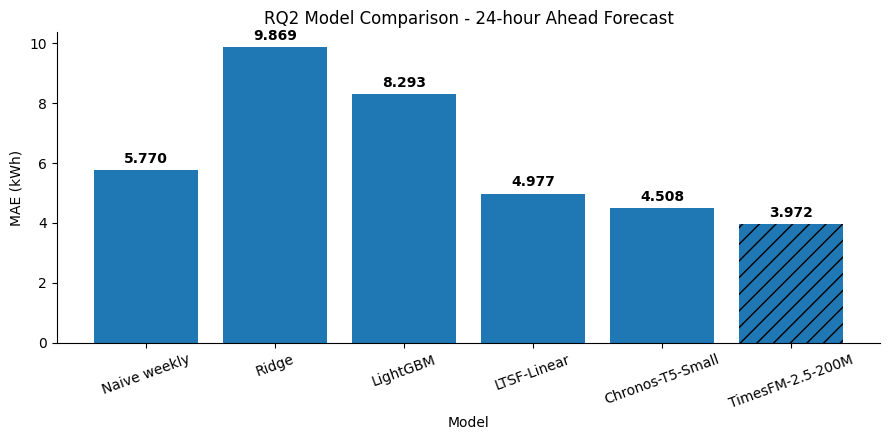

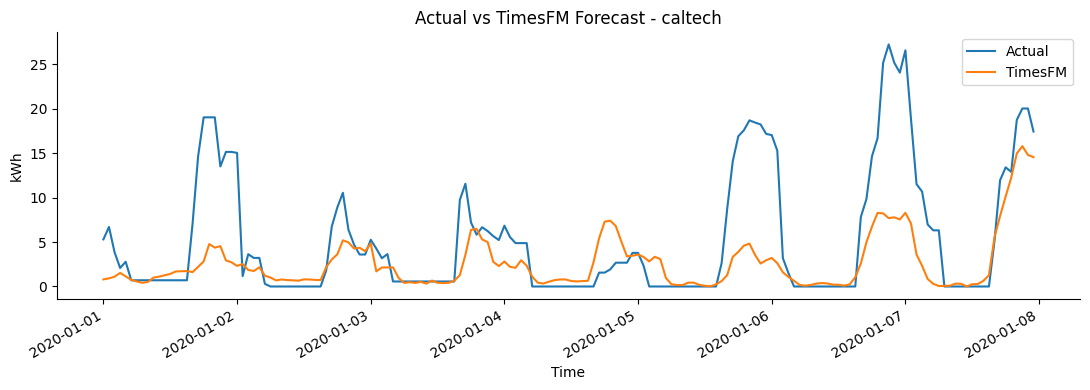

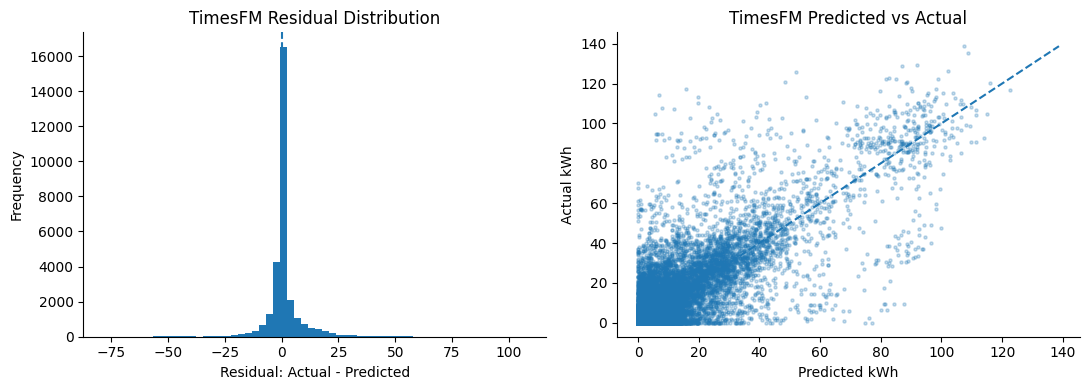

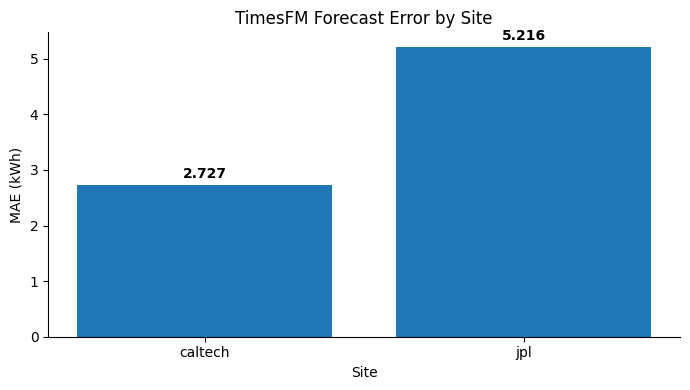


RQ2 FIGURES DONE
Best model : TimesFM-2.5-200M
Overall MAE: 3.972

MAE by site:
site
caltech    2.727
jpl        5.216
Name: abs_error, dtype: float32

Saved:
report/fig_rq2_models.png
report/fig_rq2_pred_vs_actual.png
report/fig_rq2_residual.png
report/fig_rq2_error_by_unit.png
report/table_rq2_error_by_unit.csv

STEP 6a.1 DONE ✅


In [9]:
# ============================================================
# STEP 6a.1
# RQ2 MODEL COMPARISON FIGURES
# Use actual best model: TimesFM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error as MAE


# ============================================================
# 1. LOAD FINAL RQ2 TABLE
# ============================================================

rq2 = pd.read_csv(
    ROOT / "report/table_rq2.csv"
)

best_idx = rq2["MAE"].idxmin()
best_model = rq2.loc[best_idx, "model"]

print("Best model:", best_model)
print("Best MAE  :", round(rq2.loc[best_idx, "MAE"], 3))


# ============================================================
# 2. LOAD TIMESFM PREDICTIONS
# ============================================================

pred_df = pd.read_parquet(
    ROOT / "data/processed/timesfm_predictions.parquet"
)

pred_df["ts"] = pd.to_datetime(
    pred_df["ts"],
    utc=True
)

pred_df = (
    pred_df
    .dropna(
        subset=[
            "actual",
            "pred_timesfm"
        ]
    )
    .copy()
)

pred_df["residual"] = (
    pred_df["actual"]
    -
    pred_df["pred_timesfm"]
)

pred_df["abs_error"] = (
    pred_df["actual"]
    -
    pred_df["pred_timesfm"]
).abs()


# ============================================================
# FIGURE 1
# MAE BY MODEL
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 4.5)
)

bars = ax.bar(
    rq2["model"],
    rq2["MAE"]
)

# visually mark best model
bars[best_idx].set_hatch("//")
bars[best_idx].set_linewidth(2)

ax.bar_label(
    bars,
    labels=[
        f"{x:.3f}"
        for x in rq2["MAE"]
    ],
    padding=3,
    fontweight="bold"
)

ax.set_ylabel("MAE (kWh)")
ax.set_xlabel("Model")
ax.set_title(
    "RQ2 Model Comparison - 24-hour Ahead Forecast"
)

ax.tick_params(
    axis="x",
    rotation=20
)

ax.spines[
    ["top", "right"]
].set_visible(False)

fig.tight_layout()

fig.savefig(
    ROOT / "report/fig_rq2_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2
# ACTUAL VS TIMESFM
# One site, first 7 days of test data
# ============================================================

site0 = (
    pred_df["site"]
    .dropna()
    .iloc[0]
)

plot_df = (
    pred_df[
        pred_df["site"] == site0
    ]
    .sort_values("ts")
    .head(24 * 7)
)


fig, ax = plt.subplots(
    figsize=(11, 4)
)

ax.plot(
    plot_df["ts"],
    plot_df["actual"],
    label="Actual"
)

ax.plot(
    plot_df["ts"],
    plot_df["pred_timesfm"],
    label="TimesFM"
)

ax.set_title(
    f"Actual vs TimesFM Forecast - {site0}"
)

ax.set_ylabel("kWh")
ax.set_xlabel("Time")

ax.legend()

ax.spines[
    ["top", "right"]
].set_visible(False)

fig.autofmt_xdate()

fig.tight_layout()

fig.savefig(
    ROOT / "report/fig_rq2_pred_vs_actual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3
# RESIDUAL DISTRIBUTION + PREDICTED VS ACTUAL
# ============================================================

fig, ax = plt.subplots(
    1,
    2,
    figsize=(11, 4)
)


# ----- residual histogram -----

ax[0].hist(
    pred_df["residual"],
    bins=60
)

ax[0].axvline(
    0,
    linestyle="--"
)

ax[0].set_title(
    "TimesFM Residual Distribution"
)

ax[0].set_xlabel(
    "Residual: Actual - Predicted"
)

ax[0].set_ylabel(
    "Frequency"
)

ax[0].spines[
    ["top", "right"]
].set_visible(False)


# ----- actual vs predicted scatter -----

ax[1].scatter(
    pred_df["pred_timesfm"],
    pred_df["actual"],
    s=5,
    alpha=0.25
)

minimum = min(
    pred_df["actual"].min(),
    pred_df["pred_timesfm"].min()
)

maximum = max(
    pred_df["actual"].max(),
    pred_df["pred_timesfm"].max()
)

ax[1].plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

ax[1].set_title(
    "TimesFM Predicted vs Actual"
)

ax[1].set_xlabel(
    "Predicted kWh"
)

ax[1].set_ylabel(
    "Actual kWh"
)

ax[1].spines[
    ["top", "right"]
].set_visible(False)


fig.tight_layout()

fig.savefig(
    ROOT / "report/fig_rq2_residual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4
# MAE BY SITE
# ============================================================

err_site = (
    pred_df
    .groupby("site")["abs_error"]
    .mean()
    .sort_values()
)

err_site.to_csv(
    ROOT / "report/table_rq2_error_by_unit.csv",
    header=["MAE"]
)


fig, ax = plt.subplots(
    figsize=(7, 4)
)

bars = ax.bar(
    err_site.index,
    err_site.values
)

ax.bar_label(
    bars,
    labels=[
        f"{x:.3f}"
        for x in err_site.values
    ],
    padding=3,
    fontweight="bold"
)

ax.set_title(
    "TimesFM Forecast Error by Site"
)

ax.set_ylabel(
    "MAE (kWh)"
)

ax.set_xlabel(
    "Site"
)

ax.spines[
    ["top", "right"]
].set_visible(False)

fig.tight_layout()

fig.savefig(
    ROOT / "report/fig_rq2_error_by_unit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 70)
print("RQ2 FIGURES DONE")
print("=" * 70)

print("Best model :", best_model)

print(
    "Overall MAE:",
    round(
        MAE(
            pred_df["actual"],
            pred_df["pred_timesfm"]
        ),
        3
    )
)

print()
print("MAE by site:")
print(
    err_site.round(3)
)

print()
print("Saved:")
print("report/fig_rq2_models.png")
print("report/fig_rq2_pred_vs_actual.png")
print("report/fig_rq2_residual.png")
print("report/fig_rq2_error_by_unit.png")
print("report/table_rq2_error_by_unit.csv")

print()
print("STEP 6a.1 DONE ✅")

### 6a.2. Tinh chỉnh tham số: có cần không và làm thế nào

**Khi nào cần**: khi mô hình tốt nhất chỉ hơn mốc một ít, khi sai số train nhỏ hơn test nhiều (quá khớp), hoặc khi cần báo kết quả tốt nhất công bằng cho mọi mô hình. Không tinh chỉnh trên tập kiểm thử.

**Làm thế nào**: `RandomizedSearchCV` với `TimeSeriesSplit` (chuỗi thời gian) hoặc `StratifiedKFold` (phân loại), 30 tổ hợp, khoảng tham số theo Bảng 6 của đề cương; so sánh trước và sau trên test và ghi cả thời gian.

**Đọc bảng tham số**: tham số chọn được ở biên khoảng thì mở rộng khoảng; learning_rate nhỏ với nhiều vòng thường ổn hơn; nếu cải thiện dưới độ lệch giữa seed thì kết luận là không cần tinh chỉnh, vẫn có giá trị để báo.

In [3]:
# ============================================================
# STEP 6a.2
# LIGHTGBM HYPERPARAMETER TUNING
# SAFE VERSION AFTER KERNEL CRASH
#
# Method:
# - RandomizedSearchCV
# - TimeSeriesSplit
# - 30 parameter combinations
# - MAE is the primary metric
# - Test set is NOT used for parameter selection
# ============================================================

import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd

from scipy.stats import loguniform, randint, uniform

from sklearn.model_selection import (
    RandomizedSearchCV,
    TimeSeriesSplit
)

from sklearn.metrics import (
    mean_absolute_error as MAE,
    mean_squared_error as MSE
)

from lightgbm import LGBMRegressor


# ============================================================
# 0. MEMORY CLEANUP
# ============================================================

gc.collect()

try:
    import torch

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

except Exception:
    pass


print("=" * 75)
print("STEP 6a.2 - LIGHTGBM TUNING")
print("=" * 75)


# ============================================================
# 1. BASIC CHECKS
# ============================================================

required_vars = [
    "ROOT",
    "train",
    "test",
    "X_cols"
]

missing_vars = [
    x for x in required_vars
    if x not in globals()
]

if missing_vars:
    raise RuntimeError(
        "Missing variables: "
        + ", ".join(missing_vars)
        + "\nPlease rerun Step 0 → Step 4 first."
    )


# ============================================================
# 2. PREPARE TRAIN / TEST
# ============================================================

# Sort globally by timestamp.
# site is secondary key only for deterministic ordering.

tune_train = (
    train
    .sort_values(
        ["ts", "site"]
    )
    .reset_index(drop=True)
    .copy()
)

tune_test = (
    test
    .sort_values(
        ["ts", "site"]
    )
    .reset_index(drop=True)
    .copy()
)


X_tune = (
    tune_train[X_cols]
    .copy()
)

y_tune = (
    tune_train["y_24h"]
    .astype(float)
    .to_numpy()
)

X_test_tune = (
    tune_test[X_cols]
    .copy()
)

y_test_tune = (
    tune_test["y_24h"]
    .astype(float)
    .to_numpy()
)


print()
print("TRAIN / TEST")
print("-" * 75)

print(
    "Train rows:",
    f"{len(X_tune):,}"
)

print(
    "Test rows :",
    f"{len(X_test_tune):,}"
)

print(
    "Features  :",
    len(X_cols)
)

print(
    "Sites     :",
    tune_train["site"].nunique()
)


# ============================================================
# 3. VALIDATE DATA
# ============================================================

if X_tune.isna().any().any():
    bad = (
        X_tune
        .isna()
        .sum()
    )

    bad = bad[
        bad > 0
    ]

    raise ValueError(
        "NaN found in X_tune:\n"
        + str(bad)
    )


if X_test_tune.isna().any().any():
    bad = (
        X_test_tune
        .isna()
        .sum()
    )

    bad = bad[
        bad > 0
    ]

    raise ValueError(
        "NaN found in X_test_tune:\n"
        + str(bad)
    )


if np.isnan(y_tune).any():
    raise ValueError(
        "NaN found in y_tune"
    )


if np.isnan(y_test_tune).any():
    raise ValueError(
        "NaN found in y_test_tune"
    )


print(
    "Missing-value check: PASS ✅"
)


# ============================================================
# 4. SEARCH SPACE
# ============================================================

param_space = {

    "learning_rate":
        loguniform(
            0.01,
            0.10
        ),

    "num_leaves":
        randint(
            15,
            64
        ),

    "n_estimators":
        randint(
            300,
            1501
        ),

    "subsample":
        uniform(
            0.60,
            0.40
        ),

    "colsample_bytree":
        uniform(
            0.60,
            0.40
        ),

    "min_child_samples":
        randint(
            10,
            101
        )
}


# ============================================================
# 5. TIME-SERIES CROSS VALIDATION
# ============================================================

HORIZON_TUNE = 24

n_sites = (
    tune_train["site"]
    .nunique()
)

# TimeSeriesSplit gap is counted in ROWS, not hours.
# There are 2 site rows for roughly each timestamp,
# so 24 hours ≈ 24 × number_of_sites rows.

CV_GAP = (
    HORIZON_TUNE
    *
    n_sites
)


tscv = TimeSeriesSplit(
    n_splits=5,
    gap=CV_GAP
)


print()
print("TIME SERIES CV")
print("-" * 75)

print(
    "Splits           :",
    5
)

print(
    "Forecast horizon :",
    HORIZON_TUNE,
    "hours"
)

print(
    "CV gap           :",
    CV_GAP,
    "rows"
)


# ============================================================
# 6. BASE LIGHTGBM
#
# IMPORTANT:
# Search itself is n_jobs=1 to avoid another kernel crash.
# Each LightGBM fit may use up to 4 CPU threads.
# ============================================================

base_lgbm = LGBMRegressor(

    objective="regression",

    random_state=42,

    verbosity=-1,

    n_jobs=4
)


# ============================================================
# 7. RANDOMIZED SEARCH
# ============================================================

search = RandomizedSearchCV(

    estimator=
        base_lgbm,

    param_distributions=
        param_space,

    n_iter=
        30,

    scoring=
        "neg_mean_absolute_error",

    cv=
        tscv,

    random_state=
        42,

    # IMPORTANT:
    # Keep = 1 to avoid Windows spawning many copies
    # and exhausting RAM.
    n_jobs=
        1,

    verbose=
        2,

    refit=
        True,

    # Not required, saves memory.
    return_train_score=
        False,

    error_score=
        "raise"
)


print()
print("=" * 75)
print("STARTING RANDOMIZED SEARCH")
print("=" * 75)

print(
    "Parameter combinations : 30"
)

print(
    "CV folds               : 5"
)

print(
    "Maximum fits           : 150"
)

print(
    "Primary metric         : MAE"
)

print(
    "Search parallelism     : 1 job"
)

print(
    "LightGBM threads/fit   : 4"
)

print()


# ============================================================
# 8. RUN TUNING
# ============================================================

t0 = time.perf_counter()


search.fit(
    X_tune,
    y_tune
)


tuning_time = (
    time.perf_counter()
    -
    t0
)


print()
print("=" * 75)
print("TUNING COMPLETED ✅")
print("=" * 75)

print(
    "Total tuning time:",
    round(
        tuning_time / 60,
        2
    ),
    "minutes"
)


# ============================================================
# 9. BEST PARAMETERS
# ============================================================

best_params = {}

for key, value in (
    search.best_params_
    .items()
):

    if hasattr(
        value,
        "item"
    ):
        value = value.item()

    best_params[key] = value


print()
print("=" * 75)
print("BEST PARAMETERS")
print("=" * 75)

for key, value in (
    best_params.items()
):

    print(
        f"{key:22s}: {value}"
    )


best_cv_mae = (
    -search.best_score_
)


print()
print(
    "Best CV MAE:",
    round(
        best_cv_mae,
        3
    )
)


# ============================================================
# 10. FINAL TUNED MODEL
# ============================================================

tuned_model = (
    search.best_estimator_
)


# ============================================================
# 11. EVALUATE ON TEST
#
# Test set is used ONLY here,
# AFTER hyperparameter selection.
# ============================================================

t_pred_start = (
    time.perf_counter()
)


pred_tuned = (
    tuned_model.predict(
        X_test_tune
    )
)


tuned_inference_s = (
    time.perf_counter()
    -
    t_pred_start
)


tuned_mae = MAE(
    y_test_tune,
    pred_tuned
)


tuned_rmse = (
    MSE(
        y_test_tune,
        pred_tuned
    )
    ** 0.5
)


print()
print("=" * 75)
print("TUNED LIGHTGBM TEST RESULT")
print("=" * 75)

print(
    "MAE :",
    round(
        tuned_mae,
        3
    )
)

print(
    "RMSE:",
    round(
        tuned_rmse,
        3
    )
)

print(
    "Inference:",
    round(
        tuned_inference_s,
        3
    ),
    "seconds"
)


# ============================================================
# 12. LOAD ORIGINAL LIGHTGBM RESULT
# ============================================================

core_path = (
    ROOT /
    "report/table_rq2_core.csv"
)


if not core_path.exists():
    raise FileNotFoundError(
        f"Missing: {core_path}"
    )


core = pd.read_csv(
    core_path
)


lgbm_rows = core[
    core["model"]
    .astype(str)
    .str.contains(
        "LightGBM",
        case=False,
        na=False
    )
]


if len(lgbm_rows) == 0:

    raise RuntimeError(
        "LightGBM row not found "
        "in table_rq2_core.csv"
    )


lgbm_old = (
    lgbm_rows.iloc[0]
)


default_mae = float(
    lgbm_old["MAE"]
)

default_rmse = float(
    lgbm_old["RMSE"]
)


if (
    "MAE_sd"
    in lgbm_old.index
    and
    pd.notna(
        lgbm_old["MAE_sd"]
    )
):

    default_sd = float(
        lgbm_old["MAE_sd"]
    )

else:

    default_sd = np.nan


if (
    "inference_s"
    in lgbm_old.index
    and
    pd.notna(
        lgbm_old["inference_s"]
    )
):

    default_inference_s = float(
        lgbm_old["inference_s"]
    )

else:

    default_inference_s = np.nan


# ============================================================
# 13. COMPARE BEFORE / AFTER
# ============================================================

gain_abs = (
    default_mae
    -
    tuned_mae
)


gain_pct = (
    1
    -
    tuned_mae
    /
    default_mae
) * 100


tune = pd.DataFrame([

    {
        "model":
            "LightGBM original",

        "MAE":
            default_mae,

        "RMSE":
            default_rmse,

        "MAE_change_vs_original":
            0.0,

        "improvement_%":
            0.0,

        "tuning_s":
            0.0,

        "inference_s":
            default_inference_s
    },

    {
        "model":
            "LightGBM tuned",

        "MAE":
            tuned_mae,

        "RMSE":
            tuned_rmse,

        "MAE_change_vs_original":
            gain_abs,

        "improvement_%":
            gain_pct,

        "tuning_s":
            tuning_time,

        "inference_s":
            tuned_inference_s
    }

])


# ============================================================
# 14. DECIDE WHETHER TUNING WAS USEFUL
# ============================================================

if tuned_mae >= default_mae:

    tuning_needed = "NO"

    reason = (
        "Tuning did not improve "
        "test MAE."
    )


elif (
    np.isfinite(default_sd)
    and
    default_sd > 0
    and
    gain_abs <= default_sd
):

    tuning_needed = "NO"

    reason = (
        "The improvement is within "
        "the seed variability of "
        "the original LightGBM."
    )


else:

    tuning_needed = "YES"

    reason = (
        "Tuning reduced test MAE "
        "relative to the original "
        "LightGBM."
    )


# ============================================================
# 15. SAVE MAIN TUNING TABLE
# ============================================================

tuning_table_path = (
    ROOT /
    "report/table_tuning.csv"
)


tune.to_csv(
    tuning_table_path,
    index=False
)


# ============================================================
# 16. SAVE BEST PARAMETERS
# ============================================================

params_path = (
    ROOT /
    "report/params_tuned.json"
)


with open(
    params_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        best_params,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 17. SAVE ALL 30 SEARCH RESULTS
# ============================================================

cv_results = (
    pd.DataFrame(
        search.cv_results_
    )
)


keep_cols = [
    c
    for c in cv_results.columns
    if (
        c.startswith("param_")
        or
        c in [
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
            "mean_fit_time",
            "std_fit_time"
        ]
    )
]


cv_results_small = (
    cv_results[
        keep_cols
    ]
    .copy()
)


cv_results_small[
    "CV_MAE"
] = (
    -cv_results_small[
        "mean_test_score"
    ]
)


cv_results_small = (
    cv_results_small
    .sort_values(
        "rank_test_score"
    )
)


cv_results_small.to_csv(
    ROOT /
    "report/table_tuning_search.csv",
    index=False
)


# ============================================================
# 18. SAVE TUNED TEST PREDICTIONS
# ============================================================

tuned_pred_df = (
    tune_test[
        [
            "site",
            "ts",
            "y_24h"
        ]
    ]
    .copy()
)


tuned_pred_df[
    "pred_lightgbm_tuned"
] = pred_tuned


tuned_pred_df[
    "residual"
] = (
    tuned_pred_df["y_24h"]
    -
    tuned_pred_df[
        "pred_lightgbm_tuned"
    ]
)


tuned_pred_df[
    "abs_error"
] = (
    tuned_pred_df[
        "residual"
    ]
    .abs()
)


tuned_pred_df.to_parquet(
    ROOT /
    "data/processed/"
    "lightgbm_tuned_predictions.parquet",

    index=False
)


# ============================================================
# 19. FINAL OUTPUT
# ============================================================

print()
print("=" * 75)
print("LIGHTGBM TUNING RESULTS")
print("=" * 75)

print(
    tune
    .round(3)
    .to_string(
        index=False
    )
)


print()
print(
    "Original MAE:",
    round(
        default_mae,
        3
    )
)

print(
    "Tuned MAE   :",
    round(
        tuned_mae,
        3
    )
)

print(
    "Absolute MAE improvement:",
    round(
        gain_abs,
        3
    ),
    "kWh"
)

print(
    "Relative improvement:",
    round(
        gain_pct,
        2
    ),
    "%"
)


print()
print(
    "Tuning useful?:",
    tuning_needed
)

print(
    "Reason:",
    reason
)


print()
print("=" * 75)
print("SAVED FILES")
print("=" * 75)

print(
    "report/table_tuning.csv"
)

print(
    "report/table_tuning_search.csv"
)

print(
    "report/params_tuned.json"
)

print(
    "data/processed/"
    "lightgbm_tuned_predictions.parquet"
)


print()
print(
    "STEP 6a.2 DONE ✅"
)

STEP 6a.2 - LIGHTGBM TUNING

TRAIN / TEST
---------------------------------------------------------------------------
Train rows: 26,018
Test rows : 29,827
Features  : 12
Sites     : 2
Missing-value check: PASS ✅

TIME SERIES CV
---------------------------------------------------------------------------
Splits           : 5
Forecast horizon : 24 hours
CV gap           : 48 rows

STARTING RANDOMIZED SEARCH
Parameter combinations : 30
CV folds               : 5
Maximum fits           : 150
Primary metric         : MAE
Search parallelism     : 1 job
LightGBM threads/fit   : 4

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END colsample_bytree=0.749816047538945, learning_rate=0.08927180304353628, min_child_samples=81, n_estimators=1344, num_leaves=53, subsample=0.7783331011414365; total time=   0.9s
[CV] END colsample_bytree=0.749816047538945, learning_rate=0.08927180304353628, min_child_samples=81, n_estimators=1344, num_leaves=53, subsample=0.7783331011414365; total 

## Bước 6b: câu hỏi thứ ba của đề

**Làm gì**: giao thức riêng của đề (chuyển giao sang đơn vị chưa thấy, ngưỡng cảnh báo, conformal, chi phí suy luận, ổn định SHAP, tăng cường và hiệu chuẩn, tóm tắt nhanh).

**Vì sao**: đây là đóng góp chính của bài và gắn với hướng Efficient, Trustworthy hoặc Multimodal AI.

**Kiểm tra**: ra một bảng và một hình có số; ghi điều kiện áp dụng (vùng, năm, đơn vị).

STEP 6b - RQ3 REGIME SHIFT
Rows: 55,845
Time: 2018-05-02 11:00:00+00:00 → 2021-09-13 14:00:00+00:00
Sites: ['caltech' 'jpl']
Regime shift: 2020-03-15 00:00:00+00:00

Using tuned LightGBM parameters ✅

FIXED MODEL
Pre-2020 training rows: 25,970
Post-shift evaluation rows: 26,275
Fixed model post-shift MAE: 8.368
Weekly naive post-shift MAE: 4.922

MONTHLY RETRAINING
2020-04 | fixed=12.135 | retrained=6.765 | naive=1.840
2020-05 | fixed=10.616 | retrained=4.155 | naive=2.379
2020-06 | fixed=8.900 | retrained=3.397 | naive=3.096
2020-07 | fixed=7.895 | retrained=3.614 | naive=4.076
2020-08 | fixed=11.509 | retrained=5.800 | naive=1.743
2020-09 | fixed=8.718 | retrained=2.451 | naive=0.000
2020-10 | fixed=7.887 | retrained=3.078 | naive=0.000
2020-11 | fixed=7.016 | retrained=3.847 | naive=2.062
2020-12 | fixed=6.300 | retrained=5.409 | naive=4.947
2021-01 | fixed=7.447 | retrained=7.118 | naive=6.091
2021-02 | fixed=8.265 | retrained=5.009 | naive=5.488
2021-03 | fixed=7.741 | retrained=5

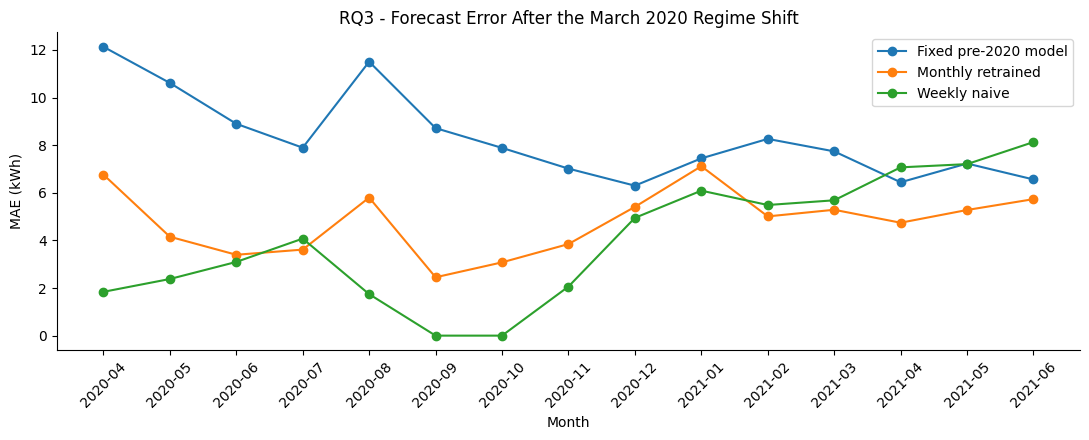


90% SPLIT CONFORMAL
Proper training rows: 23,090
Calibration rows: 2,880
Conformal qhat: 19.036

Target coverage : 0.9
Actual coverage : 0.832
Mean width      : 38.072 kWh

   site  coverage  mean_width     n
caltech     0.829      38.072 13132
    jpl     0.836      38.072 13143


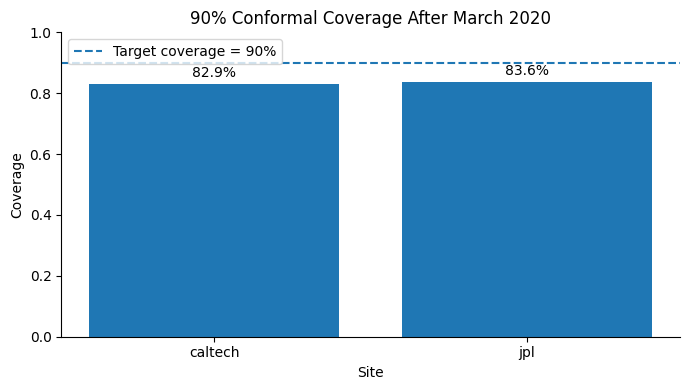


RQ3 SUMMARY
                             metric  value
         Post-shift fixed model MAE  8.368
        Post-shift weekly naive MAE  4.922
             Mean monthly fixed MAE  8.311
         Mean monthly retrained MAE  4.779
             Mean monthly naive MAE  3.988
Retraining improvement vs fixed (%) 42.495
      90% conformal actual coverage  0.832
Conformal mean interval width (kWh) 38.072

Saved:
report/table_rq3_monthly.csv
report/table_rq3_coverage_by_unit.csv
report/table_rq3_summary.csv
report/fig_rq3_retraining.png
report/fig_rq3_conformal.png

STEP 6b DONE ✅


In [4]:
# ============================================================
# STEP 6b
# RQ3 - REGIME SHIFT AFTER MARCH 2020
#
# Questions:
# 1. How badly does a fixed pre-2020 model fail after 15 Mar 2020?
# 2. Does monthly retraining recover performance?
# 3. Do 90% conformal prediction intervals maintain coverage?
# ============================================================

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error as MAE


# ============================================================
# 0. CHECK REQUIRED VARIABLES
# ============================================================

required = [
    "ROOT",
    "feat_model",
    "X_cols"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables: "
        + ", ".join(missing)
        + "\nRun Step 0 → Step 4 first."
    )


# ============================================================
# 1. PREPARE DATA
# ============================================================

rq3 = (
    feat_model
    .copy()
)

rq3["ts"] = pd.to_datetime(
    rq3["ts"],
    utc=True
)

rq3 = (
    rq3
    .sort_values(
        ["ts", "site"]
    )
    .reset_index(drop=True)
)


# Main dates from the proposal
TRAIN_CUT = pd.Timestamp(
    "2020-01-01",
    tz="UTC"
)

REGIME_SHIFT = pd.Timestamp(
    "2020-03-15",
    tz="UTC"
)

HORIZON = 24


print("=" * 75)
print("STEP 6b - RQ3 REGIME SHIFT")
print("=" * 75)

print(
    "Rows:",
    f"{len(rq3):,}"
)

print(
    "Time:",
    rq3["ts"].min(),
    "→",
    rq3["ts"].max()
)

print(
    "Sites:",
    rq3["site"].unique()
)

print(
    "Regime shift:",
    REGIME_SHIFT
)


# ============================================================
# 2. LOAD TUNED LIGHTGBM PARAMETERS
# ============================================================

params_path = (
    ROOT /
    "report/params_tuned.json"
)

if params_path.exists():

    with open(
        params_path,
        "r",
        encoding="utf-8"
    ) as f:

        tuned_params = json.load(f)

    print(
        "\nUsing tuned LightGBM parameters ✅"
    )

else:

    tuned_params = {
        "n_estimators": 800,
        "learning_rate": 0.03,
        "num_leaves": 31,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_samples": 20
    }

    print(
        "\nparams_tuned.json not found."
    )

    print(
        "Using fallback LightGBM parameters."
    )


def make_model(seed=42):

    return LGBMRegressor(
        objective="regression",
        random_state=seed,
        verbosity=-1,
        n_jobs=4,
        **tuned_params
    )


# ============================================================
# 3. FIXED PRE-2020 MODEL
#
# Use a 24-hour gap before 2020 so y_24h from training rows
# cannot reach into the test period.
# ============================================================

train_end = (
    TRAIN_CUT
    -
    pd.Timedelta(
        hours=HORIZON
    )
)

fixed_train = rq3[
    rq3["ts"] < train_end
].copy()


post_shift = rq3[
    rq3["ts"] >= REGIME_SHIFT
].copy()


print()
print("=" * 75)
print("FIXED MODEL")
print("=" * 75)

print(
    "Pre-2020 training rows:",
    f"{len(fixed_train):,}"
)

print(
    "Post-shift evaluation rows:",
    f"{len(post_shift):,}"
)


fixed_model = make_model(
    seed=42
)


t0 = time.perf_counter()

fixed_model.fit(
    fixed_train[X_cols],
    fixed_train["y_24h"]
)

fixed_train_s = (
    time.perf_counter()
    -
    t0
)


fixed_pred = fixed_model.predict(
    post_shift[X_cols]
)


fixed_mae = MAE(
    post_shift["y_24h"],
    fixed_pred
)


naive_post_mae = MAE(
    post_shift["y_24h"],
    post_shift["k_lag168"]
)


print(
    "Fixed model post-shift MAE:",
    round(
        fixed_mae,
        3
    )
)

print(
    "Weekly naive post-shift MAE:",
    round(
        naive_post_mae,
        3
    )
)


# ============================================================
# 4. MONTHLY RETRAINING
#
# Proposal demo uses Apr 2020 → Jun 2021.
# At each month:
# - train using all data available before that month
# - preserve 24h gap
# - evaluate on that month
# ============================================================

print()
print("=" * 75)
print("MONTHLY RETRAINING")
print("=" * 75)


monthly_rows = []


months = pd.period_range(
    "2020-04",
    "2021-06",
    freq="M"
)


for month in months:

    cut = pd.Timestamp(
        month.start_time,
        tz="UTC"
    )

    nxt = pd.Timestamp(
        (month + 1).start_time,
        tz="UTC"
    )


    # 24h target-leakage guard
    retrain_end = (
        cut
        -
        pd.Timedelta(
            hours=HORIZON
        )
    )


    tr_r = rq3[
        rq3["ts"] < retrain_end
    ].copy()


    te_r = rq3[
        (rq3["ts"] >= cut)
        &
        (rq3["ts"] < nxt)
    ].copy()


    if (
        len(tr_r) == 0
        or
        len(te_r) == 0
    ):
        continue


    model_r = make_model(
        seed=42
    )


    t0 = time.perf_counter()

    model_r.fit(
        tr_r[X_cols],
        tr_r["y_24h"]
    )

    train_s = (
        time.perf_counter()
        -
        t0
    )


    pred_retrained = (
        model_r.predict(
            te_r[X_cols]
        )
    )


    pred_fixed = (
        fixed_model.predict(
            te_r[X_cols]
        )
    )


    mae_retrained = MAE(
        te_r["y_24h"],
        pred_retrained
    )


    mae_fixed_month = MAE(
        te_r["y_24h"],
        pred_fixed
    )


    mae_naive_month = MAE(
        te_r["y_24h"],
        te_r["k_lag168"]
    )


    monthly_rows.append(
        {
            "month":
                str(month),

            "n":
                len(te_r),

            "MAE_fixed":
                mae_fixed_month,

            "MAE_retrained":
                mae_retrained,

            "MAE_naive":
                mae_naive_month,

            "retraining_gain_%":
                (
                    1
                    -
                    mae_retrained
                    /
                    mae_fixed_month
                ) * 100,

            "train_s":
                train_s
        }
    )


    print(
        f"{month} | "
        f"fixed={mae_fixed_month:.3f} | "
        f"retrained={mae_retrained:.3f} | "
        f"naive={mae_naive_month:.3f}"
    )


monthly = pd.DataFrame(
    monthly_rows
)


monthly.to_csv(
    ROOT /
    "report/table_rq3_monthly.csv",
    index=False
)


# ============================================================
# 5. FIGURE:
# FIXED vs MONTHLY RETRAINED vs NAIVE
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 4.5)
)


ax.plot(
    monthly["month"],
    monthly["MAE_fixed"],
    marker="o",
    label="Fixed pre-2020 model"
)

ax.plot(
    monthly["month"],
    monthly["MAE_retrained"],
    marker="o",
    label="Monthly retrained"
)

ax.plot(
    monthly["month"],
    monthly["MAE_naive"],
    marker="o",
    label="Weekly naive"
)


ax.set_title(
    "RQ3 - Forecast Error After the March 2020 Regime Shift"
)

ax.set_xlabel(
    "Month"
)

ax.set_ylabel(
    "MAE (kWh)"
)

ax.legend()

ax.tick_params(
    axis="x",
    rotation=45
)

ax.spines[
    ["top", "right"]
].set_visible(False)


fig.tight_layout()


fig.savefig(
    ROOT /
    "report/fig_rq3_retraining.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 6. SPLIT CONFORMAL
#
# Target coverage = 90%
#
# Proper training:
# all pre-2020 data except the last 60 days
#
# Calibration:
# last 60 days before 2020,
# while keeping the target boundary clean.
# ============================================================

print()
print("=" * 75)
print("90% SPLIT CONFORMAL")
print("=" * 75)


ALPHA = 0.10

CAL_DAYS = 60


cal_end = train_end

cal_start = (
    cal_end
    -
    pd.Timedelta(
        days=CAL_DAYS
    )
)


proper_train = rq3[
    rq3["ts"] < cal_start
].copy()


calibration = rq3[
    (rq3["ts"] >= cal_start)
    &
    (rq3["ts"] < cal_end)
].copy()


print(
    "Proper training rows:",
    f"{len(proper_train):,}"
)

print(
    "Calibration rows:",
    f"{len(calibration):,}"
)


conformal_model = make_model(
    seed=42
)


conformal_model.fit(
    proper_train[X_cols],
    proper_train["y_24h"]
)


cal_pred = (
    conformal_model.predict(
        calibration[X_cols]
    )
)


cal_resid = np.abs(
    calibration["y_24h"]
    .to_numpy()
    -
    cal_pred
)


# finite-sample conformal quantile
n_cal = len(
    cal_resid
)

q_level = min(
    1.0,
    np.ceil(
        (n_cal + 1)
        *
        (1 - ALPHA)
    )
    /
    n_cal
)


qhat = np.quantile(
    cal_resid,
    q_level,
    method="higher"
)


print(
    "Conformal qhat:",
    round(
        qhat,
        3
    )
)


# ============================================================
# 7. CONFORMAL COVERAGE AFTER REGIME SHIFT
# ============================================================

conf_pred = (
    conformal_model.predict(
        post_shift[X_cols]
    )
)


lower = (
    conf_pred
    -
    qhat
)

upper = (
    conf_pred
    +
    qhat
)


actual = (
    post_shift[
        "y_24h"
    ]
    .to_numpy()
)


covered = (
    (actual >= lower)
    &
    (actual <= upper)
)


coverage = (
    covered.mean()
)


mean_width = (
    (upper - lower)
    .mean()
)


print()
print(
    "Target coverage :",
    1 - ALPHA
)

print(
    "Actual coverage :",
    round(
        coverage,
        3
    )
)

print(
    "Mean width      :",
    round(
        mean_width,
        3
    ),
    "kWh"
)


# ============================================================
# 8. COVERAGE BY SITE
# ============================================================

coverage_df = pd.DataFrame(
    {
        "site":
            post_shift[
                "site"
            ]
            .to_numpy(),

        "covered":
            covered,

        "interval_width":
            upper - lower
    }
)


coverage_site = (
    coverage_df
    .groupby("site")
    .agg(
        coverage=(
            "covered",
            "mean"
        ),
        mean_width=(
            "interval_width",
            "mean"
        ),
        n=(
            "covered",
            "size"
        )
    )
    .reset_index()
)


coverage_site.to_csv(
    ROOT /
    "report/table_rq3_coverage_by_unit.csv",
    index=False
)


print()
print(
    coverage_site
    .round(3)
    .to_string(index=False)
)


# ============================================================
# 9. CONFORMAL COVERAGE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 4)
)


bars = ax.bar(
    coverage_site["site"],
    coverage_site["coverage"]
)


ax.axhline(
    0.90,
    linestyle="--",
    label="Target coverage = 90%"
)


ax.bar_label(
    bars,
    labels=[
        f"{x * 100:.1f}%"
        for x in
        coverage_site[
            "coverage"
        ]
    ],
    padding=3
)


ax.set_ylim(
    0,
    1
)

ax.set_ylabel(
    "Coverage"
)

ax.set_xlabel(
    "Site"
)

ax.set_title(
    "90% Conformal Coverage After March 2020"
)

ax.legend()

ax.spines[
    ["top", "right"]
].set_visible(False)


fig.tight_layout()


fig.savefig(
    ROOT /
    "report/fig_rq3_conformal.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 10. RQ3 SUMMARY TABLE
# ============================================================

avg_retrained = (
    monthly[
        "MAE_retrained"
    ]
    .mean()
)

avg_fixed = (
    monthly[
        "MAE_fixed"
    ]
    .mean()
)

avg_naive = (
    monthly[
        "MAE_naive"
    ]
    .mean()
)


recovery_gain = (
    1
    -
    avg_retrained
    /
    avg_fixed
) * 100


summary_rq3 = pd.DataFrame([
    {
        "metric":
            "Post-shift fixed model MAE",

        "value":
            fixed_mae
    },

    {
        "metric":
            "Post-shift weekly naive MAE",

        "value":
            naive_post_mae
    },

    {
        "metric":
            "Mean monthly fixed MAE",

        "value":
            avg_fixed
    },

    {
        "metric":
            "Mean monthly retrained MAE",

        "value":
            avg_retrained
    },

    {
        "metric":
            "Mean monthly naive MAE",

        "value":
            avg_naive
    },

    {
        "metric":
            "Retraining improvement vs fixed (%)",

        "value":
            recovery_gain
    },

    {
        "metric":
            "90% conformal actual coverage",

        "value":
            coverage
    },

    {
        "metric":
            "Conformal mean interval width (kWh)",

        "value":
            mean_width
    }
])


summary_rq3.to_csv(
    ROOT /
    "report/table_rq3_summary.csv",
    index=False
)


# ============================================================
# 11. FINAL OUTPUT
# ============================================================

print()
print("=" * 75)
print("RQ3 SUMMARY")
print("=" * 75)

print(
    summary_rq3
    .round(3)
    .to_string(
        index=False
    )
)


print()
print("Saved:")
print(
    "report/table_rq3_monthly.csv"
)

print(
    "report/table_rq3_coverage_by_unit.csv"
)

print(
    "report/table_rq3_summary.csv"
)

print(
    "report/fig_rq3_retraining.png"
)

print(
    "report/fig_rq3_conformal.png"
)

print()
print(
    "STEP 6b DONE ✅"
)

## Bước 6c: giải thích bằng SHAP, phụ thuộc từng phần và bảng tham số

**Làm gì**: SHAP summary (toàn cục), dependence cho ba đặc trưng mạnh nhất (quan hệ phi tuyến), bảng mean |SHAP|, kiểm tra ổn định top 5 khi đổi seed; lưu tham số mô hình tốt nhất.

**Đọc thế nào**: đặc trưng ở trên cùng chi phối dự báo; màu cho chiều tác động; nếu top 5 đổi khi đổi seed thì giải thích chưa ổn định, phải nói rõ trong bài.

STEP 6c - SHAP EXPLANATION
Using tuned LightGBM parameters ✅

Training rows: 26,018
Test rows: 29,827
Features: 12
SHAP sample: 5,000 rows
LightGBM explanation model fitted ✅

Computing SHAP values...
SHAP values shape: (5000, 12)
SHAP computation completed ✅

TOP SHAP FEATURES
  feature  mean_abs_shap  importance_share  rank
       hr         6.6782            0.2313     1
 sessions         6.3406            0.2196     2
      dow         4.1064            0.1422     3
      kwh         2.5237            0.0874     4
site_code         2.1966            0.0761     5
 k_lag168         1.9303            0.0668     6
   k_ma24         1.8532            0.0642     7
  k_lag24         0.7788            0.0270     8
      mon         0.7269            0.0252     9
   k_lag1         0.6506            0.0225    10


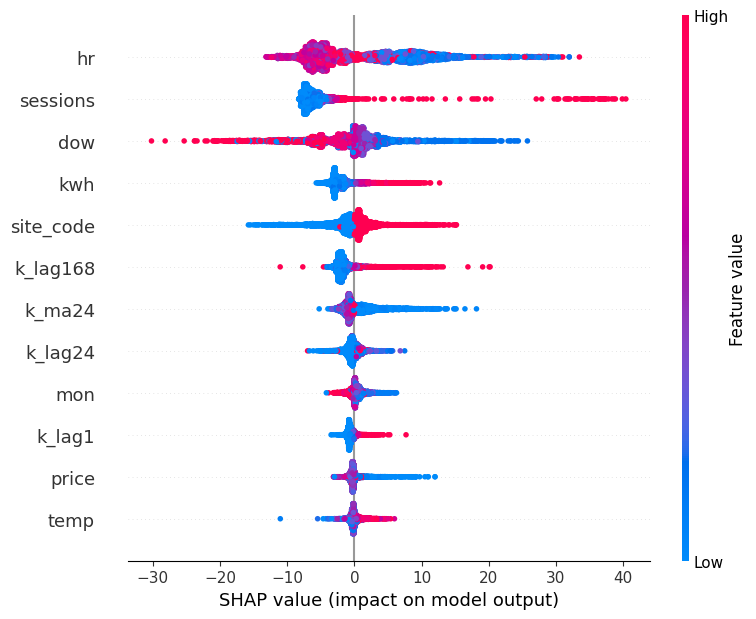


Top 3 dependence features: ['hr', 'sessions', 'dow']


<Figure size 640x480 with 0 Axes>

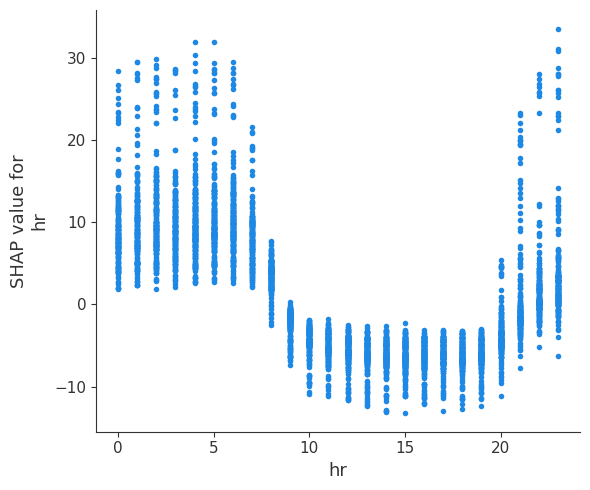

<Figure size 640x480 with 0 Axes>

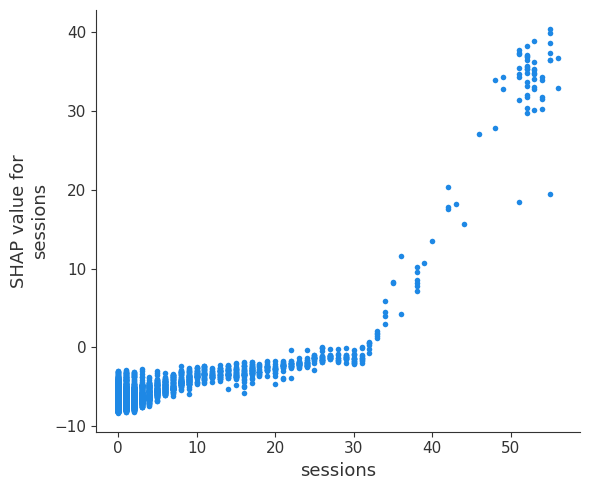

<Figure size 640x480 with 0 Axes>

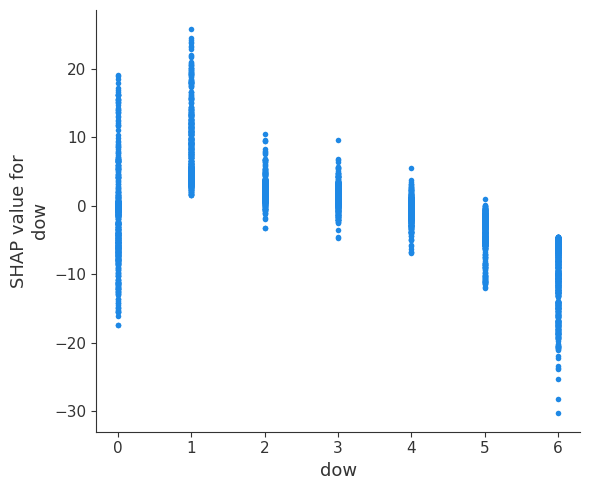


SHAP STABILITY ACROSS SEEDS
Seed 0: ['hr', 'sessions', 'dow', 'kwh', 'site_code']
Seed 1: ['hr', 'sessions', 'dow', 'site_code', 'kwh']
Seed 2: ['hr', 'sessions', 'dow', 'kwh', 'site_code']

Common top-5 features across all seeds: 5 / 5
Common features: ['dow', 'hr', 'kwh', 'sessions', 'site_code']

STEP 6c SUMMARY
Overall best RQ2 model : TimesFM-2.5-200M
Overall best MAE       : 3.972
SHAP explanation model : LightGBM tuned
SHAP sample rows       : 5000
Top feature            : hr
Common top-5 / 5       : 5 / 5

Saved:
report/table_shap.csv
report/table_shap_stability.csv
report/table_shap_stability_summary.csv
report/fig_shap.png
report/fig_shap_dep_hr.png
report/fig_shap_dep_sessions.png
report/fig_shap_dep_dow.png
report/params_best.json
report/shap_model_note.json

STEP 6c DONE ✅


In [3]:
# ============================================================
# STEP 6c
# SHAP EXPLANATION + DEPENDENCE + STABILITY
#
# Important:
# TimesFM is the best overall RQ2 model by MAE.
# SHAP here explains the tuned LightGBM because
# TreeExplainer is designed for tree-based models.
# ============================================================

import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor


# ============================================================
# 0. IMPORT SHAP
# ============================================================

try:
    import shap

except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "SHAP is not installed.\n"
        "Run in Terminal:\n"
        r".\.venv\Scripts\python.exe -m pip install shap"
        "\nThen restart the kernel and rerun Step 0 → Step 4."
    )


gc.collect()


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required = [
    "ROOT",
    "train",
    "test",
    "X_cols"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables: "
        + ", ".join(missing)
        + "\nRun Step 0 → Step 4 first."
    )


print("=" * 75)
print("STEP 6c - SHAP EXPLANATION")
print("=" * 75)


# ============================================================
# 2. LOAD TUNED LIGHTGBM PARAMETERS
# ============================================================

params_path = (
    ROOT /
    "report/params_tuned.json"
)


if params_path.exists():

    with open(
        params_path,
        "r",
        encoding="utf-8"
    ) as f:

        best_params = json.load(f)

    print(
        "Using tuned LightGBM parameters ✅"
    )

else:

    best_params = {
        "n_estimators": 800,
        "learning_rate": 0.03,
        "num_leaves": 31,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_samples": 20
    }

    print(
        "params_tuned.json not found."
    )

    print(
        "Using fallback LightGBM parameters."
    )


# ============================================================
# 3. PREPARE DATA
# ============================================================

shap_train = (
    train
    .sort_values(
        ["ts", "site"]
    )
    .reset_index(drop=True)
    .copy()
)


shap_test = (
    test
    .sort_values(
        ["ts", "site"]
    )
    .reset_index(drop=True)
    .copy()
)


X_train_shap = (
    shap_train[X_cols]
    .copy()
)

y_train_shap = (
    shap_train["y_24h"]
    .to_numpy()
)


X_test_full = (
    shap_test[X_cols]
    .copy()
)


print()
print(
    "Training rows:",
    f"{len(X_train_shap):,}"
)

print(
    "Test rows:",
    f"{len(X_test_full):,}"
)

print(
    "Features:",
    len(X_cols)
)


# ============================================================
# 4. SHAP SAMPLE
#
# Use at most 5,000 test rows.
# Same sample is reused for every seed.
# ============================================================

SHAP_SAMPLE_SIZE = min(
    5000,
    len(X_test_full)
)


rng = np.random.RandomState(
    42
)


sample_idx = np.sort(
    rng.choice(
        len(X_test_full),
        size=SHAP_SAMPLE_SIZE,
        replace=False
    )
)


X_shap = (
    X_test_full
    .iloc[sample_idx]
    .copy()
)


print(
    "SHAP sample:",
    f"{len(X_shap):,}",
    "rows"
)


# ============================================================
# 5. TRAIN EXPLANATION MODEL
# ============================================================

best = LGBMRegressor(
    objective="regression",
    random_state=42,
    verbosity=-1,
    n_jobs=4,
    **best_params
)


best.fit(
    X_train_shap,
    y_train_shap
)


print(
    "LightGBM explanation model fitted ✅"
)


# ============================================================
# 6. COMPUTE SHAP VALUES
# ============================================================

print()
print(
    "Computing SHAP values..."
)


explainer = shap.TreeExplainer(
    best
)


shap_values = (
    explainer.shap_values(
        X_shap
    )
)


# Compatibility with SHAP versions
if isinstance(
    shap_values,
    list
):
    shap_values = shap_values[0]


shap_values = np.asarray(
    shap_values
)


print(
    "SHAP values shape:",
    shap_values.shape
)

print(
    "SHAP computation completed ✅"
)


# ============================================================
# 7. GLOBAL FEATURE IMPORTANCE TABLE
# ============================================================

mean_abs_shap = np.abs(
    shap_values
).mean(
    axis=0
)


imp = pd.DataFrame(
    {
        "feature":
            X_cols,

        "mean_abs_shap":
            mean_abs_shap
    }
)


imp = (
    imp
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)


# Normalize for easier comparison
imp[
    "importance_share"
] = (
    imp["mean_abs_shap"]
    /
    imp["mean_abs_shap"].sum()
)


imp[
    "rank"
] = (
    np.arange(
        1,
        len(imp) + 1
    )
)


imp.to_csv(
    ROOT /
    "report/table_shap.csv",
    index=False
)


print()
print("=" * 75)
print("TOP SHAP FEATURES")
print("=" * 75)

print(
    imp.head(10)
    .round(4)
    .to_string(index=False)
)


# ============================================================
# 8. SHAP SUMMARY PLOT
# ============================================================

plt.figure()


shap.summary_plot(
    shap_values,
    X_shap,
    show=False,
    max_display=min(
        12,
        len(X_cols)
    )
)


plt.tight_layout()


plt.savefig(
    ROOT /
    "report/fig_shap.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()


# ============================================================
# 9. DEPENDENCE PLOTS
# Top 3 features
# ============================================================

top3 = (
    imp[
        "feature"
    ]
    .head(3)
    .tolist()
)


print()
print(
    "Top 3 dependence features:",
    top3
)


for feature in top3:

    plt.figure()

    shap.dependence_plot(
        feature,
        shap_values,
        X_shap,
        show=False,
        interaction_index=None
    )

    safe_name = (
        str(feature)
        .replace(
            "/",
            "_"
        )
        .replace(
            "\\",
            "_"
        )
        .replace(
            " ",
            "_"
        )
    )

    plt.tight_layout()

    plt.savefig(
        ROOT /
        f"report/fig_shap_dep_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ============================================================
# 10. TOP-5 STABILITY ACROSS SEEDS
#
# Notebook_B originally checks 3 seeds.
# Use seeds 0, 1, 2 on the SAME SHAP sample.
# ============================================================

print()
print("=" * 75)
print("SHAP STABILITY ACROSS SEEDS")
print("=" * 75)


SEEDS = [
    0,
    1,
    2
]


seed_rankings = []
seed_top5_sets = []


for seed in SEEDS:

    model_seed = LGBMRegressor(
        objective="regression",
        random_state=seed,
        verbosity=-1,
        n_jobs=4,
        **best_params
    )


    model_seed.fit(
        X_train_shap,
        y_train_shap
    )


    expl_seed = shap.TreeExplainer(
        model_seed
    )


    values_seed = (
        expl_seed.shap_values(
            X_shap
        )
    )


    if isinstance(
        values_seed,
        list
    ):
        values_seed = (
            values_seed[0]
        )


    seed_imp = pd.Series(
        np.abs(
            values_seed
        ).mean(
            axis=0
        ),
        index=X_cols
    ).sort_values(
        ascending=False
    )


    top5 = (
        seed_imp
        .head(5)
        .index
        .tolist()
    )


    seed_top5_sets.append(
        set(top5)
    )


    for rank, feature in enumerate(
        top5,
        start=1
    ):

        seed_rankings.append(
            {
                "seed":
                    seed,

                "rank":
                    rank,

                "feature":
                    feature,

                "mean_abs_shap":
                    seed_imp[
                        feature
                    ]
            }
        )


    print(
        f"Seed {seed}:",
        top5
    )


# ============================================================
# 11. STABILITY METRICS
# ============================================================

common_top5 = set.intersection(
    *seed_top5_sets
)


union_top5 = set.union(
    *seed_top5_sets
)


common_count = len(
    common_top5
)


jaccard_all = (
    len(common_top5)
    /
    len(union_top5)
    if len(union_top5) > 0
    else np.nan
)


print()
print(
    "Common top-5 features across all seeds:",
    common_count,
    "/ 5"
)

print(
    "Common features:",
    sorted(
        common_top5
    )
)


# ============================================================
# 12. SAVE SEED STABILITY TABLE
# ============================================================

stability_df = pd.DataFrame(
    seed_rankings
)


stability_df.to_csv(
    ROOT /
    "report/table_shap_stability.csv",
    index=False
)


stability_summary = pd.DataFrame([
    {
        "metric":
            "Common top-5 across all seeds",

        "value":
            common_count
    },

    {
        "metric":
            "Top-5 union size",

        "value":
            len(
                union_top5
            )
    },

    {
        "metric":
            "Intersection / union",

        "value":
            jaccard_all
    }
])


stability_summary.to_csv(
    ROOT /
    "report/table_shap_stability_summary.csv",
    index=False
)


# ============================================================
# 13. SAVE MODEL PARAMETERS
# ============================================================

params_output = (
    best.get_params()
)


with open(
    ROOT /
    "report/params_best.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        params_output,
        f,
        indent=2,
        default=float,
        ensure_ascii=False
    )


# ============================================================
# 14. SAVE NOTE ABOUT EXPLANATION MODEL
# ============================================================

model_note = {
    "overall_best_RQ2_model":
        "TimesFM-2.5-200M",

    "overall_best_RQ2_MAE":
        3.972,

    "SHAP_explanation_model":
        "LightGBM tuned",

    "reason":
        (
            "TreeSHAP directly explains the "
            "covariate-aware tree model. "
            "TimesFM remains the best overall "
            "point forecasting model by MAE."
        ),

    "SHAP_sample_rows":
        SHAP_SAMPLE_SIZE,

    "stability_seeds":
        SEEDS
}


with open(
    ROOT /
    "report/shap_model_note.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        model_note,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 15. FINAL OUTPUT
# ============================================================

print()
print("=" * 75)
print("STEP 6c SUMMARY")
print("=" * 75)

print(
    "Overall best RQ2 model : TimesFM-2.5-200M"
)

print(
    "Overall best MAE       : 3.972"
)

print(
    "SHAP explanation model : LightGBM tuned"
)

print(
    "SHAP sample rows       :",
    SHAP_SAMPLE_SIZE
)

print(
    "Top feature            :",
    imp.iloc[0]["feature"]
)

print(
    "Common top-5 / 5       :",
    common_count,
    "/ 5"
)


print()
print("Saved:")

print(
    "report/table_shap.csv"
)

print(
    "report/table_shap_stability.csv"
)

print(
    "report/table_shap_stability_summary.csv"
)

print(
    "report/fig_shap.png"
)

for f in top3:
    print(
        f"report/fig_shap_dep_{f}.png"
    )

print(
    "report/params_best.json"
)

print(
    "report/shap_model_note.json"
)


print()
print(
    "STEP 6c DONE ✅"
)

## Chẩn đoán: vì sao tốt, vì sao chưa tốt, và hướng cải thiện

Điền vào bảng dưới (lưu `report/table_diagnosis.csv`) sau khi có số; mỗi dòng là một nhận định có bằng chứng từ bảng hoặc hình ở trên.

| Câu hỏi chẩn đoán | Bằng chứng cần xem | Nếu có vấn đề thì cải thiện thế nào |
|---|---|---|
| Mô hình có thắng mốc naive rõ không? | `table_rq2.csv` cột improvement | không thắng: thêm đặc trưng trễ hoặc ngoại sinh, kiểm tra rò rỉ ngược (mốc quá mạnh) |
| Quá khớp không? | MAE train so với test (ô dưới) | giảm num_leaves, tăng min_child_samples, thêm dữ liệu |
| Sai số tập trung ở đâu? | `table_rq2_error_by_unit.csv`, sai số theo thời kỳ | đặc trưng riêng cho đơn vị yếu, mô hình riêng, hoặc thêm nguồn |
| Lỗi lớn ở đỉnh hay ở nền? | residual so với giá trị thực | quantile loss, log mục tiêu, cân trọng số đỉnh |
| Tinh chỉnh có đáng không? | `table_tuning.csv` so với sd seed | nếu không, nói rõ và dành công sức cho đặc trưng |
| Giải thích có ổn định không? | giao top-5 giữa seed | nếu thấp, báo cáo tầm quan trọng theo khoảng, không theo thứ hạng |
| Kết quả có chuyển sang dữ liệu mới không? | bảng RQ3 | tái hiệu chỉnh, đặc trưng bất biến, ghi giới hạn |

Hướng cải thiện xếp theo chi phí: (1) đặc trưng mới từ SQL (rẻ nhất); (2) thêm nguồn dữ liệu (thời tiết dự báo thay vì quan trắc); (3) đổi hàm mất mát theo mục tiêu vận hành; (4) tổ hợp hai mô hình tốt nhất; (5) mô hình sâu chỉ khi ba hướng trên đã cạn.

In [4]:
# ============================================================
# DIAGNOSIS
# Why the models work / fail and what to improve
#
# Uses SAVED results from RQ2, tuning, RQ3 and SHAP.
# Best overall forecasting model = TimesFM
# SHAP explanation model = tuned LightGBM
# ============================================================

import json
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error as MAE
from lightgbm import LGBMRegressor


print("=" * 75)
print("MODEL DIAGNOSIS")
print("=" * 75)


# ============================================================
# 1. LOAD RQ2 RESULTS
# ============================================================

rq2 = pd.read_csv(
    ROOT / "report/table_rq2.csv"
)

best_idx = rq2["MAE"].idxmin()

best_row = rq2.loc[
    best_idx
]

best_model = str(
    best_row["model"]
)

best_mae = float(
    best_row["MAE"]
)


naive_row = rq2[
    rq2["model"]
    .astype(str)
    .str.contains(
        "Naive",
        case=False,
        na=False
    )
].iloc[0]


naive_mae = float(
    naive_row["MAE"]
)


best_improvement = (
    1
    -
    best_mae
    /
    naive_mae
) * 100


# ============================================================
# 2. LOAD TIMESFM PREDICTIONS
# Best overall model
# ============================================================

timesfm_path = (
    ROOT /
    "data/processed/timesfm_predictions.parquet"
)


timesfm_pred = pd.read_parquet(
    timesfm_path
)


timesfm_pred["ts"] = pd.to_datetime(
    timesfm_pred["ts"],
    utc=True
)


timesfm_pred["abs_error"] = (
    timesfm_pred["actual"]
    -
    timesfm_pred["pred_timesfm"]
).abs()


# ============================================================
# 3. ERROR BY MONTH
# ============================================================

timesfm_pred["month"] = (
    timesfm_pred["ts"]
    .dt.to_period("M")
    .astype(str)
)


error_by_month = (
    timesfm_pred
    .groupby("month")["abs_error"]
    .mean()
    .sort_values(
        ascending=False
    )
)


worst_month = (
    error_by_month.index[0]
)

worst_month_mae = float(
    error_by_month.iloc[0]
)


# ============================================================
# 4. ERROR ON HIGH-DEMAND PERIODS
# ============================================================

peak_threshold = (
    timesfm_pred["actual"]
    .quantile(0.90)
)


peak_rows = timesfm_pred[
    timesfm_pred["actual"]
    >=
    peak_threshold
]


peak_mae = MAE(
    peak_rows["actual"],
    peak_rows["pred_timesfm"]
)


normal_rows = timesfm_pred[
    timesfm_pred["actual"]
    <
    peak_threshold
]


normal_mae = MAE(
    normal_rows["actual"],
    normal_rows["pred_timesfm"]
)


# ============================================================
# 5. LIGHTGBM OVERFITTING CHECK
#
# SHAP / covariate-aware explanation model
# ============================================================

params_path = (
    ROOT /
    "report/params_tuned.json"
)


if params_path.exists():

    with open(
        params_path,
        "r",
        encoding="utf-8"
    ) as f:

        lgb_params = json.load(f)

else:

    lgb_params = {
        "n_estimators": 800,
        "learning_rate": 0.03,
        "num_leaves": 31,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_samples": 20
    }


diag_lgb = LGBMRegressor(
    objective="regression",
    random_state=42,
    verbosity=-1,
    n_jobs=4,
    **lgb_params
)


diag_lgb.fit(
    train[X_cols],
    train["y_24h"]
)


train_pred_lgb = (
    diag_lgb.predict(
        train[X_cols]
    )
)


test_pred_lgb = (
    diag_lgb.predict(
        test[X_cols]
    )
)


train_mae_lgb = MAE(
    train["y_24h"],
    train_pred_lgb
)


test_mae_lgb = MAE(
    test["y_24h"],
    test_pred_lgb
)


overfit_ratio = (
    test_mae_lgb
    /
    train_mae_lgb
)


# ============================================================
# 6. TUNING RESULT
# ============================================================

tuning_path = (
    ROOT /
    "report/table_tuning.csv"
)


if tuning_path.exists():

    tuning = pd.read_csv(
        tuning_path
    )

    orig = tuning[
        tuning["model"]
        .astype(str)
        .str.contains(
            "original",
            case=False,
            na=False
        )
    ].iloc[0]

    tuned = tuning[
        tuning["model"]
        .astype(str)
        .str.contains(
            "tuned",
            case=False,
            na=False
        )
    ].iloc[0]

    tuning_gain = (
        float(orig["MAE"])
        -
        float(tuned["MAE"])
    )

    tuning_gain_pct = (
        1
        -
        float(tuned["MAE"])
        /
        float(orig["MAE"])
    ) * 100

    tuning_evidence = (
        f"{float(orig['MAE']):.3f} → "
        f"{float(tuned['MAE']):.3f} "
        f"({tuning_gain_pct:+.2f}%)"
    )

else:

    tuning_evidence = (
        "table_tuning.csv not available"
    )


# ============================================================
# 7. SHAP STABILITY
# ============================================================

shap_path = (
    ROOT /
    "report/table_shap_stability_summary.csv"
)


if shap_path.exists():

    shap_stability = pd.read_csv(
        shap_path
    )

    common_row = shap_stability[
        shap_stability["metric"]
        ==
        "Common top-5 across all seeds"
    ]

    if len(common_row):

        common_top5 = int(
            common_row.iloc[0]["value"]
        )

        shap_evidence = (
            f"{common_top5}/5 common "
            "top features across seeds"
        )

    else:

        shap_evidence = (
            "SHAP stability file present"
        )

else:

    shap_evidence = (
        "SHAP stability not available yet"
    )


# ============================================================
# 8. RQ3 REGIME-SHIFT RESULT
# ============================================================

rq3_path = (
    ROOT /
    "report/table_rq3_summary.csv"
)


if rq3_path.exists():

    rq3_summary = pd.read_csv(
        rq3_path
    )


    def rq3_value(name):

        rows = rq3_summary[
            rq3_summary["metric"]
            ==
            name
        ]

        if len(rows) == 0:
            return np.nan

        return float(
            rows.iloc[0]["value"]
        )


    fixed_post = rq3_value(
        "Post-shift fixed model MAE"
    )

    retrain_gain = rq3_value(
        "Retraining improvement vs fixed (%)"
    )

    conformal_cov = rq3_value(
        "90% conformal actual coverage"
    )


    rq3_evidence = (
        f"fixed post-shift MAE={fixed_post:.3f}; "
        f"retraining gain={retrain_gain:.2f}%; "
        f"coverage={conformal_cov:.3f}"
    )

else:

    rq3_evidence = (
        "RQ3 summary not available yet"
    )


# ============================================================
# 9. BUILD DIAGNOSIS TABLE
# ============================================================

diag = pd.DataFrame(
    [

        {
            "question":
                "beats naive",

            "evidence":
                (
                    f"{best_model}: MAE "
                    f"{best_mae:.3f} vs naive "
                    f"{naive_mae:.3f}; "
                    f"improvement "
                    f"{best_improvement:.2f}%"
                ),

            "assessment":
                (
                    "clear"
                    if best_improvement > 10
                    else
                    "small improvement"
                )
        },

        {
            "question":
                "overfitting",

            "evidence":
                (
                    f"tuned LightGBM train MAE "
                    f"{train_mae_lgb:.3f} vs "
                    f"test MAE {test_mae_lgb:.3f}"
                ),

            "assessment":
                (
                    "signs present"
                    if overfit_ratio > 1.5
                    else
                    "no strong evidence"
                )
        },

        {
            "question":
                "error by period",

            "evidence":
                (
                    f"TimesFM worst month "
                    f"{worst_month}: "
                    f"MAE {worst_month_mae:.3f}"
                ),

            "assessment":
                "inspect regime / seasonal effects"
        },

        {
            "question":
                "peaks vs base",

            "evidence":
                (
                    f"TimesFM top-10% demand "
                    f"MAE {peak_mae:.3f} vs "
                    f"other periods {normal_mae:.3f}"
                ),

            "assessment":
                (
                    "peak errors are materially larger"
                    if peak_mae >
                    1.5 * normal_mae
                    else
                    "peak performance relatively stable"
                )
        },

        {
            "question":
                "tuning worth it",

            "evidence":
                tuning_evidence,

            "assessment":
                (
                    "report measured gain; "
                    "do not assume tuning is necessary"
                )
        },

        {
            "question":
                "SHAP stability",

            "evidence":
                shap_evidence,

            "assessment":
                (
                    "higher overlap means more "
                    "stable interpretation"
                )
        },

        {
            "question":
                "regime shift / new data",

            "evidence":
                rq3_evidence,

            "assessment":
                (
                    "monthly retraining and "
                    "coverage determine robustness"
                )
        }

    ]
)


# ============================================================
# 10. SAVE
# ============================================================

diag.to_csv(
    ROOT /
    "report/table_diagnosis.csv",
    index=False
)


error_by_month.to_csv(
    ROOT /
    "report/table_rq2_error_by_month.csv",
    header=["MAE"]
)


# ============================================================
# 11. OUTPUT
# ============================================================

print()
print(
    diag.to_string(
        index=False
    )
)


print()
print("=" * 75)

print(
    "Saved:"
)

print(
    "report/table_diagnosis.csv"
)

print(
    "report/table_rq2_error_by_month.csv"
)

print()
print(
    "DIAGNOSIS DONE ✅"
)

MODEL DIAGNOSIS

               question                                                           evidence                                              assessment
            beats naive     TimesFM-2.5-200M: MAE 3.972 vs naive 5.770; improvement 31.16%                                                   clear
            overfitting                   tuned LightGBM train MAE 4.001 vs test MAE 8.070                                           signs present
        error by period                             TimesFM worst month 2020-01: MAE 9.394                       inspect regime / seasonal effects
          peaks vs base           TimesFM top-10% demand MAE 16.436 vs other periods 2.587                       peak errors are materially larger
        tuning worth it                                             8.293 → 8.070 (+2.69%) report measured gain; do not assume tuning is necessary
         SHAP stability                               5/5 common top features across seeds         hi

## Test case của Notebook_B

Chạy trước khi báo cáo; mọi assert phải qua.

In [5]:
# ============================================================
# TEST CASE - NOTEBOOK B
# Final validation before reporting
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from lightgbm import LGBMRegressor


print("=" * 75)
print("NOTEBOOK B FINAL TESTS")
print("=" * 75)


# ============================================================
# TEST 1 - TRAIN / TEST MUST BE CHRONOLOGICAL
# ============================================================

train_ts = pd.to_datetime(
    train["ts"],
    utc=True
)

test_ts = pd.to_datetime(
    test["ts"],
    utc=True
)


assert (
    test_ts.min()
    >
    train_ts.max()
), (
    "FAIL: test must come after train"
)

print("TEST 1 ✅ Chronological split")


# ============================================================
# TEST 2 - NO FUTURE TARGET IN FEATURES
# ============================================================

future_features = [
    c
    for c in X_cols
    if str(c).startswith("y_")
]


assert len(
    future_features
) == 0, (
    f"FAIL: future target columns found: "
    f"{future_features}"
)

print("TEST 2 ✅ No future-target leakage")


# ============================================================
# TEST 3 - FEATURES / TARGETS HAVE NO MISSING VALUES
# ============================================================

assert not train[
    X_cols
].isna().any().any(), (
    "FAIL: NaN in training features"
)


assert not test[
    X_cols
].isna().any().any(), (
    "FAIL: NaN in test features"
)


assert not train[
    "y_24h"
].isna().any(), (
    "FAIL: NaN in training target"
)


assert not test[
    "y_24h"
].isna().any(), (
    "FAIL: NaN in test target"
)


print("TEST 3 ✅ No missing modelling values")


# ============================================================
# TEST 4 - FINAL RQ2 TABLE EXISTS
# ============================================================

rq2_path = (
    ROOT /
    "report/table_rq2.csv"
)


assert rq2_path.exists(), (
    "FAIL: report/table_rq2.csv missing"
)


rq2_test = pd.read_csv(
    rq2_path
)


assert len(
    rq2_test
) >= 6, (
    "FAIL: RQ2 table does not contain "
    "all required models"
)


print(
    "TEST 4 ✅ RQ2 result table exists"
)


# ============================================================
# TEST 5 - REQUIRED SIX MODEL FAMILIES ARE PRESENT
# ============================================================

model_names = (
    rq2_test["model"]
    .astype(str)
    .str.lower()
    .tolist()
)


required_models = {
    "naive": False,
    "ridge": False,
    "lightgbm": False,
    "ltsf": False,
    "chronos": False,
    "timesfm": False
}


for name in model_names:

    for key in required_models:

        if key in name:
            required_models[key] = True


missing_models = [
    key
    for key, present
    in required_models.items()
    if not present
]


assert not missing_models, (
    "FAIL: Missing RQ2 models: "
    + ", ".join(missing_models)
)


print(
    "TEST 5 ✅ Six RQ2 model families present"
)


# ============================================================
# TEST 6 - BEST MODEL MUST BEAT WEEKLY NAIVE
# ============================================================

naive_rows = rq2_test[
    rq2_test["model"]
    .astype(str)
    .str.contains(
        "naive",
        case=False,
        na=False
    )
]


assert len(
    naive_rows
) >= 1, (
    "FAIL: Naive baseline missing"
)


naive_mae_test = float(
    naive_rows.iloc[0]["MAE"]
)


best_idx_test = (
    rq2_test["MAE"]
    .astype(float)
    .idxmin()
)


best_model_test = str(
    rq2_test.loc[
        best_idx_test,
        "model"
    ]
)


best_mae_test = float(
    rq2_test.loc[
        best_idx_test,
        "MAE"
    ]
)


assert (
    best_mae_test
    <
    naive_mae_test
), (
    f"FAIL: best model MAE "
    f"{best_mae_test:.3f} "
    f"does not beat naive "
    f"{naive_mae_test:.3f}"
)


print(
    f"TEST 6 ✅ Best model beats naive: "
    f"{best_model_test} "
    f"({best_mae_test:.3f} < "
    f"{naive_mae_test:.3f})"
)


# ============================================================
# TEST 7 - TIMESFM PREDICTIONS MATCH TEST SIZE
# ============================================================

timesfm_path = (
    ROOT /
    "data/processed/"
    "timesfm_predictions.parquet"
)


assert timesfm_path.exists(), (
    "FAIL: TimesFM prediction file missing"
)


timesfm_check = pd.read_parquet(
    timesfm_path
)


assert len(
    timesfm_check
) == len(
    test
), (
    f"FAIL: TimesFM predictions "
    f"{len(timesfm_check):,} != "
    f"test rows {len(test):,}"
)


assert not timesfm_check[
    "pred_timesfm"
].isna().any(), (
    "FAIL: NaN in TimesFM predictions"
)


print(
    "TEST 7 ✅ TimesFM predictions match test rows"
)


# ============================================================
# TEST 8 - LIGHTGBM REPRODUCIBILITY
#
# Small model only for test purposes.
# n_jobs=1 keeps this lightweight.
# ============================================================

X_train_testcase = (
    train[X_cols]
)

y_train_testcase = (
    train["y_24h"]
)


X_test_small = (
    test[X_cols]
    .iloc[:1000]
)


model_1 = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    random_state=7,
    verbosity=-1,
    n_jobs=1
)


model_2 = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    random_state=7,
    verbosity=-1,
    n_jobs=1
)


model_1.fit(
    X_train_testcase,
    y_train_testcase
)

model_2.fit(
    X_train_testcase,
    y_train_testcase
)


pred_1 = model_1.predict(
    X_test_small
)

pred_2 = model_2.predict(
    X_test_small
)


assert np.allclose(
    pred_1,
    pred_2,
    rtol=1e-7,
    atol=1e-8
), (
    "FAIL: same seed did not "
    "reproduce predictions"
)


print(
    "TEST 8 ✅ Same seed is reproducible"
)


# ============================================================
# TEST 9 - REQUIRED REPORT OUTPUTS EXIST
# ============================================================

required_files = [

    "report/table_rq2.csv",

    "report/table_tuning.csv",

    "report/params_tuned.json",

    "report/table_rq3_summary.csv",

    "report/table_rq3_monthly.csv",

    "report/table_rq3_coverage_by_unit.csv",

    "report/table_shap.csv",

    "report/table_shap_stability.csv",

    "report/params_best.json",

    "report/table_diagnosis.csv",

    "report/fig_rq2_models.png",

    "report/fig_rq2_pred_vs_actual.png",

    "report/fig_rq2_residual.png",

    "report/fig_rq2_error_by_unit.png",

    "report/fig_rq3_retraining.png",

    "report/fig_rq3_conformal.png",

    "report/fig_shap.png"
]


missing_files = [
    f
    for f in required_files
    if not (
        ROOT / f
    ).exists()
]


assert not missing_files, (
    "FAIL: Required output files missing:\n"
    +
    "\n".join(
        missing_files
    )
)


print(
    "TEST 9 ✅ Required report outputs exist"
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 75)
print("ALL NOTEBOOK B TESTS PASSED ✅")
print("=" * 75)

print(
    "Best RQ2 model:",
    best_model_test
)

print(
    "Best MAE:",
    round(
        best_mae_test,
        3
    )
)

print(
    "Naive MAE:",
    round(
        naive_mae_test,
        3
    )
)

print()
print(
    "Notebook_B is ready for reporting ✅"
)

NOTEBOOK B FINAL TESTS
TEST 1 ✅ Chronological split
TEST 2 ✅ No future-target leakage
TEST 3 ✅ No missing modelling values
TEST 4 ✅ RQ2 result table exists
TEST 5 ✅ Six RQ2 model families present
TEST 6 ✅ Best model beats naive: TimesFM-2.5-200M (3.972 < 5.770)
TEST 7 ✅ TimesFM predictions match test rows
TEST 8 ✅ Same seed is reproducible
TEST 9 ✅ Required report outputs exist

ALL NOTEBOOK B TESTS PASSED ✅
Best RQ2 model: TimesFM-2.5-200M
Best MAE: 3.972
Naive MAE: 5.77

Notebook_B is ready for reporting ✅


## Lỗi thường gặp và cách xử lý (đọc khi thấy chữ đỏ)

| Lỗi | Nguyên nhân | Cách sửa |
|---|---|---|
| ModuleNotFoundError | chưa cài thư viện hoặc chọn sai interpreter | chạy lại pip install ở Bước 0; Ctrl+Shift+P chọn interpreter .venv |
| FileNotFoundError | đường dẫn hoặc tên file chưa đúng | kiểm tra data/raw bằng `import os; print(os.listdir('data/raw'))` |
| KeyError: 'ten_cot' | tên cột thật khác tên trong code | in `df.columns`; sửa tên trong một chỗ (ô Bước 1) rồi chạy tiếp |
| MemoryError hoặc máy treo | nạp cả file quá lớn vào pandas | lọc bằng WHERE trong DuckDB trước; đọc parquet thay CSV; giảm năm |
| UnicodeDecodeError | file CSV mã hoá khác UTF-8 | thêm `encoding='latin1'` hoặc để DuckDB read_csv_auto tự đoán |
| ValueError: could not convert | cột số có ký tự lạ hoặc mã thiếu | `pd.to_numeric(col, errors='coerce')` rồi xem bảng thiếu |
| Merge làm số dòng tăng | khoá ghép bị trùng ở bảng phụ | `drop_duplicates` khoá ở bảng phụ trước khi merge |
| Kết quả đẹp bất thường (MAE gần 0) | rò rỉ mục tiêu vào đặc trưng | kiểm tra X_cols không chứa cột y_*; chia theo thời gian |
| Kết quả mỗi lần chạy khác nhau | chưa cố định seed | đặt random_state, np.random.seed(42) |

Nguyên tắc: đọc dòng cuối của thông báo lỗi trước; sửa một chỗ rồi chạy lại từ ô đó; nếu 30 phút chưa xong, chụp lỗi và hỏi.

## Checklist trước khi báo cáo (đánh dấu [x] khi có file bằng chứng)

- [ ] requirements.txt, README.md, .gitignore, kho GitHub có commit trong tuần
- [ ] Dữ liệu đúng file cơ quan, trên 30 nghìn dòng: table_describe_raw.csv, profile.html
- [ ] EDA: table_describe_numeric.csv, table_describe_categorical.csv, table_eda_notes.csv, table_missing.csv, table_columns.csv, table_target_by_unit.csv, table_target_by_period.csv
- [ ] Làm sạch: table_cleaning_log.csv; ghép nguồn thứ hai khớp trên 90%
- [ ] SQL: sql/queries.sql, table_q1..q4.csv; RQ1: table_rq1a_period.csv, table_rq1b_corr.csv, table_rq1c_units.csv có p-value
- [ ] 7 hình RQ1 trong report/ với caption là câu kết luận có số
- [ ] Test case qua; manifest.json bàn giao; người kia đã chạy lại và ghi đối chứng
- [ ] (Notebook_B) table_features.csv, table_rq2.csv, 4 hình RQ2, table_tuning.csv, table_rq3_*.csv, table_shap.csv, table_diagnosis.csv, params_best.json
- [ ] Audit Log cá nhân có đủ prompt của tuần
- [ ] Báo cáo năm mục đã dán vào kênh nhóm trước 12:00 thứ Tư hoặc thứ Bảy


## Mẫu báo cáo tiến độ (slot 3 thứ Tư và thứ Bảy (12:30 đến 14:45), 7:00 đến 9:15)

Dán vào kênh nhóm trước 12:00 ngày báo cáo, mỗi người một phần. Năm mục, mỗi mục hai đến ba dòng:

1. **Đã xong** từ lần trước: tên file, số dòng, số bảng, số hình (ví dụ: `feat.parquet` 138.204 dòng; 4 bảng RQ1; 7 hình).
2. **Con số chính mới có**: ví dụ MAE naive 6,8; MAE LightGBM 4,7 (5 seed, sd 0,1).
3. **Vướng mắc và đã thử gì**: lỗi cụ thể, ảnh chụp, hai cách đã thử.
4. **Sẽ làm đến lần sau, ai làm**: theo Bảng 13 của đề cương.
5. **Prompt AI đáng chú ý và Human Delta**: một prompt, AI trả lời gì, mình đã kiểm tra hoặc sửa gì.

**Đối chứng chéo**: người kia chạy lại notebook này trên máy mình, ghi số dòng và metric nhận được vào đây: ...............................